# Risk-aware last-mile routing for scheduled parcel delivery (Bengaluru)

**Pipeline:** scheduled parcels → failure-risk model *P(fail | parcel, arrival time)* ∥ GNN travel-time model → cost matrix → OR-Tools VRP (+ local search) → plan, evaluated by re-simulation.

```
  tomorrow's parcels ──► Failure-risk ML ──► P(fail | X, τ) curves ─┐
                                                                     ├─► cost matrix ─► VRP / OR-Tools ─► plan
  OSM road network ────► GNN travel time ──► t̂_ij per hour slot ────┘
```

**Data honesty.** Everything except the road geometry is **synthetic**. The road network is real (OpenStreetMap, Koramangala / BTM / HSR / Madiwala). Customer behaviour, traffic, parcels and outcomes come from `simulator.py`, a documented generative world. The pipeline below only reads the *observable* files in `data/`. The hidden truth in `ground_truth/` is used only (a) to score plans by re-simulating them and (b) in diagnostics that are labelled **[synthetic-only diagnostic]**.

Run top to bottom (Runtime → Run all). Set `FAST = True` for a shorter run (~20 min including data generation); the full setting takes roughly 35–50 min on a free Colab CPU.

In [19]:
import os, sys, subprocess, time, json, math, warnings
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx", "ortools", "folium"], check=True)
warnings.filterwarnings("ignore")

In [20]:
# ---------------- run configuration ----------------
FAST = False                 # True: fewer evaluation days and shorter solver limits
USE_OSM = True               # real Bengaluru roads from OpenStreetMap (needs internet)
WORK = "/content/lastmile" if IN_COLAB else os.path.abspath("lastmile_run")
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
sys.path.insert(0, WORK)

N_EVAL_DAYS = 5 if FAST else 10      # test days re-planned by every planner
SOLVER_SECONDS = 8 if FAST else 12   # OR-Tools time limit per planner per day
LS_SECONDS = 5 if FAST else 8        # local-search time limit per planner per day
SEED = 42
print("working dir:", WORK)

working dir: /content/lastmile


### The world simulator (`simulator.py`)
This cell writes the simulator to disk. It is **the world, not the product**: it holds the hidden customer behaviour and traffic. The pipeline below never imports its internals except to (a) generate the data once, (b) score plans by re-simulation, and (c) labelled diagnostics. Every behavioural and cost number is an assumption collected in `CONFIG`.

In [21]:
%%writefile simulator.py
"""
simulator.py  --  the synthetic Bangalore last-mile world.

THIS FILE IS THE WORLD, NOT THE PRODUCT.
It plays the role of reality: real road geometry (OpenStreetMap), hidden
customer behaviour, hidden traffic, and the courier's legacy operations that
produced the historical records. The pipeline notebook may only read the
OBSERVABLE files written to data/. The hidden ground truth (ground_truth/,
world.pkl) is used for exactly two things:
  1. scoring a delivery plan (re-simulating it with the true behaviour), and
  2. clearly labelled diagnostics (e.g. predicted vs true failure curves).

Every behavioural or cost number below is an ASSUMPTION. They are collected
in CONFIG so the report can list them and the team can replace them with
cited figures. Nothing here is real customer data.
"""
from __future__ import annotations

import math
import os
import pickle
import time

import numpy as np
import pandas as pd
import networkx as nx
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

# ----------------------------------------------------------------------------
# Configuration (all assumptions)
# ----------------------------------------------------------------------------
CONFIG = dict(
    seed=42,
    # Koramangala / BTM / HSR / Madiwala, south-east Bengaluru (~4.9 x 4.4 km)
    bbox=dict(west=77.605, south=12.905, east=77.650, north=12.945),
    hub_latlon=(12.9255, 77.6280),          # delivery hub (assumed location)
    start_date="2026-06-01",
    n_days=120,                             # Jun-Sep 2026 (monsoon months)
    # staggered rider shifts (start_h, end_h): morning / mid / evening riders
    rider_shifts=[(9.0, 15.0), (9.0, 15.0), (12.0, 18.0), (12.0, 18.0),
                  (14.5, 20.5), (14.5, 20.5)],
    first_hour=9, n_slots=12,               # hourly slots 09:00 ... 20:00+
    n_customers=6000,
    apartment_share=0.55,
    customers_per_building=(4, 14),
    new_orders_per_day=200,
    rider_capacity=50,
    max_attempts=3,
    # behaviour mix (hidden)
    type_probs=dict(office=0.30, home=0.40, evening=0.12, irregular=0.18),
    poor_address_share=0.12,
    impulse_buyer_share=0.12,
    requested_slot_share=0.25,
    # costs in INR (assumptions; replace with cited numbers in the report)
    cost=dict(
        per_km=3.0,              # 2-wheeler fuel/energy + maintenance
        per_rider_min=2.0,       # rider time (~INR 120 / hour)
        per_overtime_min=4.0,    # after shift end
        per_failed_attempt=90.0, # next-day re-attempt + handling + customer service
        per_deferral=70.0,       # next-day attempt + SLA slip, no wasted trip
        per_sla_min=1.0,         # per minute outside a requested slot
    ),
)

SLOTS_CUSTOMER = dict(morning=(9.0, 12.0), afternoon=(12.0, 16.0), evening=(16.0, 20.0))

HIGHWAY_FF_KMPH = dict(  # typical free-flow speed by road class (assumption)
    motorway=45, trunk=40, primary=32, secondary=28, tertiary=24,
    unclassified=20, residential=18, living_street=12, service=12)
HIGHWAY_CONGESTION_BASE = dict(
    motorway=0.6, trunk=0.6, primary=0.55, secondary=0.45, tertiary=0.35,
    unclassified=0.22, residential=0.15, living_street=0.10, service=0.10)
HIGHWAY_DEFAULT_LANES = dict(
    motorway=3, trunk=3, primary=2, secondary=2, tertiary=1,
    unclassified=1, residential=1, living_street=1, service=1)

# congestion hotspots (approximate locations; assumption)
HOTSPOTS = [
    # name, lat, lon, strength, radius_m
    ("Silk Board junction", 12.9177, 77.6230, 0.9, 700),
    ("Sony World junction", 12.9367, 77.6262, 0.5, 500),
    ("Agara junction", 12.9236, 77.6503, 0.6, 600),
    ("Forum / Hosur Road", 12.9346, 77.6110, 0.5, 500),
    ("HSR BDA complex", 12.9116, 77.6380, 0.4, 500),
    ("Madiwala", 12.9220, 77.6170, 0.5, 450),
]

# time-of-day congestion profile, slots 09..20 (index 0 = 09:00-10:00)
PEAK_PROFILE = np.array([1.00, 0.80, 0.55, 0.45, 0.45, 0.50, 0.55, 0.70,
                         0.95, 1.00, 0.85, 0.65])


def slot_of(hour):
    """hour (float, 24h clock) -> slot index 0..n_slots-1"""
    h = np.asarray(hour, dtype=float)
    return np.clip(np.floor(h).astype(int) - CONFIG["first_hour"], 0, CONFIG["n_slots"] - 1)


def band_of(hour):
    """hour -> 0 morning [9,12), 1 afternoon [12,16), 2 evening [16,..)"""
    h = np.asarray(hour, dtype=float)
    return np.where(h < 12, 0, np.where(h < 16, 1, 2))


def _sig(x):
    return 1.0 / (1.0 + np.exp(-x))


def haversine_m(lat1, lon1, lat2, lon2):
    R = 6371000.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1
    dl = np.radians(np.asarray(lon2) - np.asarray(lon1))
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


# ----------------------------------------------------------------------------
# Road network
# ----------------------------------------------------------------------------
def _norm_highway(h):
    if isinstance(h, (list, tuple)):
        h = h[0]
    h = str(h).replace("_link", "")
    return h if h in HIGHWAY_FF_KMPH else "unclassified"


def _parse_lanes(x, hw):
    if isinstance(x, (list, tuple)):
        x = x[0]
    try:
        v = int(float(str(x).split(";")[0]))
        return max(1, min(v, 4))
    except Exception:
        return HIGHWAY_DEFAULT_LANES[hw]


def build_network_osm(bbox):
    """Download the drivable road network from OpenStreetMap (needs internet)."""
    import osmnx as ox
    w, s, e, n = bbox["west"], bbox["south"], bbox["east"], bbox["north"]
    try:
        G = ox.graph_from_bbox((w, s, e, n), network_type="drive")       # osmnx >= 2.0
    except TypeError:
        G = ox.graph_from_bbox(n, s, e, w, network_type="drive")         # osmnx 1.x
    nodes = pd.DataFrame(
        [(nid, d["y"], d["x"]) for nid, d in G.nodes(data=True)],
        columns=["osmid", "lat", "lon"])
    rows = []
    for u, v, _, d in G.edges(keys=True, data=True):
        hw = _norm_highway(d.get("highway", "unclassified"))
        rows.append((u, v, float(d.get("length", 1.0)), hw,
                     _parse_lanes(d.get("lanes"), hw), bool(d.get("oneway", False))))
    edges = pd.DataFrame(rows, columns=["u_osm", "v_osm", "length_m", "highway", "lanes", "oneway"])
    return nodes, edges, "OpenStreetMap (osmnx, network_type='drive')"


def build_network_fallback(bbox, rng, spacing_m=110.0):
    """Procedural stand-in network over the same bbox. Used ONLY if OSM is
    unreachable; the notebook prints a loud warning when this happens."""
    lat0 = (bbox["south"] + bbox["north"]) / 2
    m_per_deg_lat = 111_320.0
    m_per_deg_lon = 111_320.0 * math.cos(math.radians(lat0))
    ny = int((bbox["north"] - bbox["south"]) * m_per_deg_lat / spacing_m) + 1
    nx_ = int((bbox["east"] - bbox["west"]) * m_per_deg_lon / spacing_m) + 1
    lat = bbox["south"] + np.arange(ny) * spacing_m / m_per_deg_lat
    lon = bbox["west"] + np.arange(nx_) * spacing_m / m_per_deg_lon
    LA, LO = np.meshgrid(lat, lon, indexing="ij")
    LA = LA + rng.normal(0, 18, LA.shape) / m_per_deg_lat
    LO = LO + rng.normal(0, 18, LO.shape) / m_per_deg_lon
    nid = np.arange(ny * nx_).reshape(ny, nx_)
    nodes = pd.DataFrame(dict(osmid=nid.ravel(), lat=LA.ravel(), lon=LO.ravel()))

    def cls(i, horizontal):
        if i % 12 == 6:
            return "primary"
        if i % 6 == 3:
            return "secondary"
        if i % 3 == 0:
            return "tertiary"
        return "residential"

    rows = []
    for i in range(ny):
        for j in range(nx_):
            for (di, dj, horiz) in ((0, 1, True), (1, 0, False)):
                ii, jj = i + di, j + dj
                if ii >= ny or jj >= nx_:
                    continue
                hw = cls(i if horiz else j, horiz)
                if hw == "residential" and rng.random() < 0.18:
                    continue
                a, b = nid[i, j], nid[ii, jj]
                L = float(haversine_m(LA[i, j], LO[i, j], LA[ii, jj], LO[ii, jj]))
                for (x, y) in ((a, b), (b, a)):
                    rows.append((x, y, L, hw, HIGHWAY_DEFAULT_LANES[hw], False))
    edges = pd.DataFrame(rows, columns=["u_osm", "v_osm", "length_m", "highway", "lanes", "oneway"])
    return nodes, edges, "PROCEDURAL FALLBACK (OpenStreetMap was unreachable)"


def finalize_network(nodes, edges):
    # collapse parallel edges (keep the shortest), drop self loops
    edges = edges[edges.u_osm != edges.v_osm]
    edges = edges.sort_values("length_m").drop_duplicates(["u_osm", "v_osm"]).copy()
    G = nx.DiGraph()
    G.add_edges_from(zip(edges.u_osm, edges.v_osm))
    scc = max(nx.strongly_connected_components(G), key=len)
    nodes = nodes[nodes.osmid.isin(scc)].reset_index(drop=True)
    nodes["node_id"] = np.arange(len(nodes))
    idmap = dict(zip(nodes.osmid, nodes.node_id))
    edges = edges[edges.u_osm.isin(scc) & edges.v_osm.isin(scc)].copy()
    edges["u"] = edges.u_osm.map(idmap).astype(int)
    edges["v"] = edges.v_osm.map(idmap).astype(int)
    edges = edges.sort_values(["u", "v"]).reset_index(drop=True)
    edges["edge_id"] = np.arange(len(edges))
    edges["length_m"] = edges.length_m.clip(lower=1.0)
    edges["speed_limit_kmph"] = edges.highway.map(HIGHWAY_FF_KMPH).astype(float)
    edges["ff_time_s"] = edges.length_m / (edges.speed_limit_kmph / 3.6)
    nodes = nodes[["node_id", "osmid", "lat", "lon"]]
    edges = edges[["edge_id", "u", "v", "length_m", "highway", "lanes", "oneway",
                   "speed_limit_kmph", "ff_time_s"]]
    return nodes, edges


class Graph:
    """CSR helpers shared by the simulator and the pipeline."""

    def __init__(self, nodes, edges):
        self.N = len(nodes)
        self.E = len(edges)
        self.u = edges.u.values.astype(np.int64)
        self.v = edges.v.values.astype(np.int64)
        self.length = edges.length_m.values.astype(float)
        self.key = self.u * self.N + self.v       # sorted because edges sorted by (u,v)

    def csr(self, w):
        return csr_matrix((np.asarray(w, float), (self.u, self.v)), shape=(self.N, self.N))

    def edge_lookup(self, a, b):
        k = np.asarray(a, np.int64) * self.N + np.asarray(b, np.int64)
        idx = np.searchsorted(self.key, k)
        return idx

    def matrix(self, w, nodes_list, chunk=400):
        """shortest-path cost matrix among nodes_list under edge weights w"""
        nodes_list = np.asarray(nodes_list)
        A = self.csr(w)
        out = np.empty((len(nodes_list), len(nodes_list)), dtype=np.float32)
        for s in range(0, len(nodes_list), chunk):
            d = dijkstra(A, indices=nodes_list[s:s + chunk])
            out[s:s + chunk] = d[:, nodes_list]
        return out


# ----------------------------------------------------------------------------
# The world
# ----------------------------------------------------------------------------
class World:
    def __init__(self, cfg=CONFIG, use_osm=True, verbose=True):
        self.cfg = cfg
        self.rng = np.random.default_rng(cfg["seed"])
        t0 = time.time()
        if use_osm:
            try:
                nodes, edges, src = build_network_osm(cfg["bbox"])
            except Exception as e:  # noqa
                print("!! OpenStreetMap download failed:", repr(e)[:200])
                nodes, edges, src = build_network_fallback(cfg["bbox"], self.rng)
        else:
            nodes, edges, src = build_network_fallback(cfg["bbox"], self.rng)
        self.network_source = src
        self.nodes, self.edges = finalize_network(nodes, edges)
        self.G = Graph(self.nodes, self.edges)
        if verbose:
            print(f"road network: {src} | nodes={self.G.N:,} edges={self.G.E:,} "
                  f"({time.time()-t0:.1f}s)")
        self.dates = pd.date_range(cfg["start_date"], periods=cfg["n_days"], freq="D")
        self._make_hub()
        self._make_traffic()
        self._make_weather()
        self._make_customers()
        self._slot_csr_cache = {}

    # ---------------- hub ----------------
    def _make_hub(self):
        lat, lon = self.cfg["hub_latlon"]
        arterial = self.edges.highway.isin(["primary", "secondary", "tertiary"])
        cand = np.unique(np.r_[self.edges.u[arterial], self.edges.v[arterial]])
        if len(cand) == 0:
            cand = self.nodes.node_id.values
        d = haversine_m(lat, lon, self.nodes.lat.values[cand], self.nodes.lon.values[cand])
        self.hub_node = int(cand[np.argmin(d)])

    # ---------------- traffic (hidden) ----------------
    def _approx_load(self, n_sources=250):
        """Sampled edge betweenness on free-flow times: a structural property
        of the network that is NOT given to the pipeline as a feature."""
        rng = np.random.default_rng(self.cfg["seed"] + 1)
        A = self.G.csr(self.edges.ff_time_s.values)
        srcs = rng.choice(self.G.N, size=min(n_sources, self.G.N), replace=False)
        usage = np.zeros(self.G.E)
        dist, pred = dijkstra(A, indices=srcs, return_predecessors=True)
        for k in range(len(srcs)):
            p = pred[k]
            order = np.argsort(-np.where(np.isfinite(dist[k]), dist[k], -1))
            size = np.ones(self.G.N)
            par = p[order]
            ok = par >= 0
            for t, pp, o in zip(order, par, ok):
                if o:
                    size[pp] += size[t]
            t_ok = order[ok]
            eid = self.G.edge_lookup(par[ok], t_ok)
            np.add.at(usage, eid, size[t_ok])
        load = np.log1p(usage)
        return (load - load.min()) / (load.max() - load.min() + 1e-9)

    def _make_traffic(self):
        rng = np.random.default_rng(self.cfg["seed"] + 2)
        e = self.edges
        mid_lat = (self.nodes.lat.values[e.u] + self.nodes.lat.values[e.v]) / 2
        mid_lon = (self.nodes.lon.values[e.u] + self.nodes.lon.values[e.v]) / 2
        hot = np.zeros(self.G.E)
        for _, la, lo, st, r in HOTSPOTS:
            d = haversine_m(mid_lat, mid_lon, la, lo)
            hot += st * np.exp(-0.5 * (d / r) ** 2)
        self.edge_load = self._approx_load()
        het = rng.lognormal(0, 0.25, self.G.E)
        base_cls = e.highway.map(HIGHWAY_CONGESTION_BASE).values
        self.edge_base = (base_cls + 0.6 * self.edge_load + hot) * het
        self.edge_hotspot = hot
        arterial = e.highway.isin(["motorway", "trunk", "primary", "secondary"]).values
        self.edge_profile = np.where(arterial[None, :],
                                     0.3 + 0.7 * PEAK_PROFILE[:, None],
                                     0.5 + 0.5 * PEAK_PROFILE[:, None])  # (slots, E)

    def _make_weather(self):
        rng = np.random.default_rng(self.cfg["seed"] + 3)
        p_rain = {6: 0.45, 7: 0.50, 8: 0.50, 9: 0.55, 10: 0.45}
        rows = []
        for d in self.dates:
            rain = rng.random() < p_rain.get(d.month, 0.3)
            evening = rain and rng.random() < 0.7
            rows.append((d.date().isoformat(), d.dayofweek, int(rain), int(evening)))
        self.weather = pd.DataFrame(rows, columns=["date", "dow", "rain_day", "rain_evening"])
        dayf = np.where(self.weather.dow == 6, 0.6, np.where(self.weather.dow == 5, 0.8, 1.0))
        self.day_factor = dayf * rng.lognormal(0, 0.10, len(self.dates))
        self.slot_noise = rng.lognormal(0, 0.06, (len(self.dates), self.cfg["n_slots"]))

    def rain_slots(self, d):
        """bool array (n_slots,) -- slots with rain on day d"""
        w = self.weather.iloc[d]
        hours = self.cfg["first_hour"] + np.arange(self.cfg["n_slots"])
        if not w.rain_day:
            return np.zeros(self.cfg["n_slots"], bool)
        if w.rain_evening:
            return hours >= 16
        return np.ones(self.cfg["n_slots"], bool)

    def true_multiplier(self, d):
        """(n_slots, E) true travel-time multiplier over free-flow on day d."""
        rng = np.random.default_rng([self.cfg["seed"], 1000 + d])
        incident = rng.lognormal(0, 0.10, self.G.E)
        rain = np.where(self.rain_slots(d), 1.4, 1.0)
        cong = (self.edge_base[None, :] * self.edge_profile * self.day_factor[d]
                * rain[:, None] * self.slot_noise[d][:, None] * incident[None, :])
        return 1.0 + cong

    def true_edge_times(self, d):
        return self.edges.ff_time_s.values[None, :] * self.true_multiplier(d)

    def _slot_csr(self, d):
        if d not in self._slot_csr_cache:
            if len(self._slot_csr_cache) > 3:
                self._slot_csr_cache.clear()
            T = self.true_edge_times(d)
            self._slot_csr_cache[d] = (T, [self.G.csr(T[s]) for s in range(T.shape[0])])
        return self._slot_csr_cache[d]

    # ---------------- customers (hidden behaviour) ----------------
    def _make_customers(self):
        cfg, rng = self.cfg, np.random.default_rng(self.cfg["seed"] + 4)
        n = cfg["n_customers"]
        e = self.edges
        res = e.highway.isin(["residential", "living_street", "unclassified", "tertiary"])
        w = np.bincount(e.u[res], minlength=self.G.N) + 0.2
        w[self.hub_node] = 0
        w = w / w.sum()
        # apartments: buildings with several customers at one node
        is_apt = rng.random(n) < cfg["apartment_share"]
        n_apt = is_apt.sum()
        node = np.empty(n, int)
        lo, hi = cfg["customers_per_building"]
        n_build = int(n_apt / ((lo + hi) / 2)) + 1
        build_nodes = rng.choice(self.G.N, size=n_build, p=w, replace=False)
        node[is_apt] = rng.choice(build_nodes, size=n_apt)
        node[~is_apt] = rng.choice(self.G.N, size=n - n_apt, p=w)

        types = np.array(list(cfg["type_probs"].keys()))
        p = np.array(list(cfg["type_probs"].values()))
        ctype = np.empty(n, dtype=object)
        # apartments (IT-corridor flats) slightly more likely to be office-goers
        p_apt = p * np.array([1.25, 0.85, 1.0, 0.9]); p_apt /= p_apt.sum()
        ctype[is_apt] = rng.choice(types, size=n_apt, p=p_apt)
        ctype[~is_apt] = rng.choice(types, size=n - n_apt, p=p)

        poor_addr = rng.random(n) < cfg["poor_address_share"]
        impulse = rng.random(n) < cfg["impulse_buyer_share"]
        C = pd.DataFrame(dict(
            customer_id=[f"C{i:05d}" for i in range(n)],
            node_id=node,
            address_type=np.where(is_apt, "apartment", "independent_house"),
            ctype=ctype,
            hi=rng.beta(18, 2, n),                 # P(someone home) when 'in'
            lo=rng.beta(6, 4, n),                  # P(someone in household home) when customer 'out'
            leave=np.clip(rng.normal(9.3, 0.5, n), 7.5, 11.0),
            ret=np.clip(rng.normal(18.6, 0.8, n), 16.0, 21.5),
            back=np.clip(rng.normal(14.5, 1.0, n), 11.5, 18.0),
            dip_center=rng.uniform(10.5, 17.5, n),
            dip_depth=rng.uniform(0.05, 0.45, n),
            wk_out_center=rng.uniform(11.0, 18.0, n),
            irr_base=rng.uniform(0.60, 0.85, n),
            irr_amp=rng.uniform(0.10, 0.25, n),
            irr_phase=rng.uniform(0, 24, n),
            irr_period=rng.uniform(6, 12, n),
            security_accept=np.where(is_apt, rng.beta(8, 2, n), 0.0),
            addr_fail=np.where(poor_addr, rng.beta(2, 25, n), rng.beta(1, 300, n)),
            poor_address=poor_addr,
            has_landmark=np.where(poor_addr, rng.random(n) < 0.25, rng.random(n) < 0.80),
            refusal=np.where(impulse, rng.beta(3, 9, n), rng.beta(1, 40, n)),
            impulse=impulse,
            cod_pref=rng.beta(1.2, 1.8, n),
            activity=rng.lognormal(0, 1.0, n),
        ))
        C["lat"] = self.nodes.lat.values[C.node_id]
        C["lon"] = self.nodes.lon.values[C.node_id]
        self.customers = C
        self.cidx = {c: i for i, c in enumerate(C.customer_id)}
        # irregular customers: day-to-day phase shift (hidden)
        self.irr_shift = rng.uniform(-2.0, 2.0, (n, len(self.dates)))

    # ---------------- true behaviour ----------------
    def presence(self, ci, hours, d, perturb=None):
        """P(someone accepts the parcel in person) for customers ci (n,) at
        hours (n, H) on day d. Hidden ground truth."""
        C = self.customers
        ci = np.asarray(ci)
        h = np.asarray(hours, float)
        if h.ndim == 1:
            h = h[:, None]
        dow = int(self.weather.dow.iloc[d])
        weekend = dow >= 5
        typ = C.ctype.values[ci]
        hi = C.hi.values[ci][:, None]
        lo = C.lo.values[ci][:, None]
        leave = C.leave.values[ci][:, None]
        ret = C.ret.values[ci][:, None]
        back = C.back.values[ci][:, None]
        if perturb:
            leave = leave + perturb.get("leave_shift", 0.0)
            ret = ret + perturb.get("return_shift", 0.0)
            back = back + perturb.get("back_shift", 0.0)
        wdt = 0.25
        p = np.empty_like(h)
        # office-goers
        m = typ == "office"
        if m.any():
            if not weekend:
                out = _sig((h[m] - leave[m]) / wdt) * _sig((ret[m] - h[m]) / wdt)
                p[m] = hi[m] - (hi[m] - lo[m]) * out
            else:
                c = C.wk_out_center.values[ci[m]][:, None]
                p[m] = 0.85 * hi[m] - 0.35 * np.exp(-0.5 * ((h[m] - c) / 1.2) ** 2)
        m = typ == "home"
        if m.any():
            c = C.dip_center.values[ci[m]][:, None]
            dd = C.dip_depth.values[ci[m]][:, None]
            p[m] = hi[m] - dd * np.exp(-0.5 * ((h[m] - c) / 1.0) ** 2)
        m = typ == "evening"
        if m.any():
            b = back[m] - (2.0 if weekend else 0.0)
            p[m] = lo[m] + (hi[m] - lo[m]) * _sig((h[m] - b) / wdt)
        m = typ == "irregular"
        if m.any():
            cim = ci[m]
            ph = C.irr_phase.values[cim] + self.irr_shift[cim, d] * (
                perturb.get("irregular_noise", 1.0) if perturb else 1.0)
            p[m] = (C.irr_base.values[cim][:, None] + C.irr_amp.values[cim][:, None]
                    * np.sin(2 * np.pi * (h[m] - ph[:, None]) / C.irr_period.values[cim][:, None]))
        rain = self.rain_slots(d)[slot_of(h)]
        p = np.where(rain, p + 0.06 * (1 - p), p)
        return np.clip(p, 0.01, 0.99)

    def refusal_prob(self, ci, is_cod, order_age, value, perturb=None):
        r = self.customers.refusal.values[np.asarray(ci)]
        r = r * (1 + 0.12 * np.maximum(np.asarray(order_age) - 3, 0)) * \
            (1 + 0.3 * (np.asarray(value) > 2000))
        if perturb:
            r = r * perturb.get("refusal_mult", 1.0)
        return np.where(np.asarray(is_cod).astype(bool), np.clip(r, 0, 0.9), 0.0)

    def true_fail_curve(self, parcels, hours, d, perturb=None):
        """TRUE P(first attempt fails) for each parcel row at each hour.
        parcels needs customer_id, is_cod, order_age_days, order_value_inr."""
        ci = parcels.customer_id.map(self.cidx).values
        H = np.broadcast_to(np.asarray(hours, float), (len(ci), len(hours)))
        pres = self.presence(ci, H, d, perturb)
        C = self.customers
        sec = np.where(parcels.is_cod.values.astype(bool), 0.0, C.security_accept.values[ci])[:, None]
        pref = self.refusal_prob(ci, parcels.is_cod.values, parcels.order_age_days.values,
                                 parcels.order_value_inr.values, perturb)[:, None]
        pa = C.addr_fail.values[ci][:, None]
        return pa + (1 - pa) * ((1 - pres) * (1 - sec) + pres * pref)

    def outcome(self, prow, arrival_h, d, perturb=None):
        """Realised outcome of one attempt using the parcel's common random numbers."""
        ci = self.cidx[prow.customer_id]
        C = self.customers
        if prow.u_addr < C.addr_fail.values[ci]:
            return "failed", "address_issue", False
        pres = self.presence(np.array([ci]), np.array([[arrival_h]]), d, perturb)[0, 0]
        if prow.u_present < pres:
            pref = self.refusal_prob(np.array([ci]), np.array([prow.is_cod]),
                                     np.array([prow.order_age_days]),
                                     np.array([prow.order_value_inr]), perturb)[0]
            if prow.u_refuse < pref:
                return "failed", "refused", False
            return "delivered", "", False
        if (not prow.is_cod) and prow.u_security < C.security_accept.values[ci]:
            return "delivered", "", True
        return "failed", "not_home", False

    def service_min(self, prow, delivered):
        ci = self.cidx[prow.customer_id]
        apt = self.customers.address_type.values[ci] == "apartment"
        if not delivered:
            base = 4.0
        else:
            base = 3.0 + 1.5 * bool(prow.is_cod) + 2.0 * apt
        return base * math.exp(0.2 * prow.z_service)

    def planned_service_min(self, parcels):
        """Expected service time a planner can compute from observable fields."""
        apt = (parcels.customer_id.map(dict(zip(self.customers.customer_id,
                                                self.customers.address_type))) == "apartment")
        return 3.0 + 1.5 * parcels.is_cod.values.astype(float) + 2.0 * apt.values

    # ---------------- orders ----------------
    def _new_orders(self, d, rng, counter):
        cfg = self.cfg
        dow = int(self.weather.dow.iloc[d])
        n = rng.poisson(cfg["new_orders_per_day"] * (0.85 if dow == 6 else 1.0))
        C = self.customers
        pa = C.activity.values / C.activity.values.sum()
        ci = np.unique(rng.choice(len(C), size=n, p=pa))
        n = len(ci)
        is_cod = rng.random(n) < C.cod_pref.values[ci]
        value = np.round(np.exp(rng.normal(6.7, 0.8, n)), 0)
        weight = np.round(np.exp(rng.normal(np.log(0.8), 0.6, n)), 2)
        age = np.clip(1 + rng.poisson(2.0, n), 1, 10)
        req = np.array([""] * n, dtype=object)
        wants = rng.random(n) < cfg["requested_slot_share"]
        if wants.any():
            names = list(SLOTS_CUSTOMER)
            mids = np.array([[10.5, 14.0, 18.0]] * wants.sum())
            pr = self.presence(ci[wants], mids, d)
            best = pr.argmax(1)
            rnd = rng.integers(0, 3, wants.sum())
            pick = np.where(rng.random(wants.sum()) < 0.75, best, rnd)
            req[wants] = [names[k] for k in pick]
        df = pd.DataFrame(dict(
            parcel_id=[f"P{counter + k:07d}" for k in range(n)],
            customer_id=C.customer_id.values[ci],
            is_cod=is_cod.astype(int),
            order_value_inr=value,
            weight_kg=weight,
            order_age_days=age,
            requested_slot=req,
        ))
        return df

    def _draws(self, df, rng):
        n = len(df)
        df = df.copy()
        df["u_addr"] = rng.random(n)
        df["u_present"] = rng.random(n)
        df["u_refuse"] = rng.random(n)
        df["u_security"] = rng.random(n)
        df["z_service"] = rng.normal(0, 1, n)
        return df

    # ---------------- legacy planner (what the courier did historically) ----------
    def _legacy_plan(self, manifest, rng):
        K, cap = len(self.cfg["rider_shifts"]), self.cfg["rider_capacity"]
        lat0, lon0 = self.nodes.lat.values[self.hub_node], self.nodes.lon.values[self.hub_node]
        nodes = manifest.node_id.values
        ang = np.arctan2(self.nodes.lat.values[nodes] - lat0,
                         (self.nodes.lon.values[nodes] - lon0) * math.cos(math.radians(lat0)))
        rot = rng.uniform(0, 2 * np.pi)
        order = np.argsort((ang - rot) % (2 * np.pi))
        n = len(order)
        n_use = min(n, K * cap)
        chunks = np.array_split(order[:n_use], K)
        routes = []
        for ch in chunks:
            if len(ch) == 0:
                routes.append([])
                continue
            pos = [self.sidx[x] for x in nodes[ch]]
            left = list(range(len(ch)))
            cur = self.sidx[self.hub_node]
            seq = []
            while left:
                dd = self.static_dist[cur, [pos[k] for k in left]]
                k = left.pop(int(np.argmin(dd)))
                seq.append(ch[k])
                cur = pos[k]
            if rng.random() < 0.5:
                seq = seq[::-1]
            routes.append(list(manifest.parcel_id.values[seq]))
        routes = [routes[k] for k in rng.permutation(K)]   # sector -> random shift
        deferred = list(manifest.parcel_id.values[order[n_use:]])
        return routes, deferred

    # ---------------- execute a plan in the true world ----------------
    def execute(self, d, manifest, routes, deferred=(), perturb=None, record_gps=False,
                start_offsets=None, true_mats=None):
        """Run routes (list of lists of parcel_id) on day d with true traffic and
        true behaviour. Returns (attempt_rows, rider_rows, gps_rows)."""
        cfg = self.cfg
        M = manifest.set_index("parcel_id")
        T, A = self._slot_csr(d)
        hub = self.hub_node
        att, riders, gps = [], [], []
        for k, route in enumerate(routes):
            t = cfg["rider_shifts"][k][0] + (start_offsets[k] if start_offsets is not None else 10 / 60)
            t_start = t
            cur = hub
            km = 0.0
            stops = list(route) + [None]
            for seq, pid in enumerate(stops):
                nxt = hub if pid is None else int(M.at[pid, "node_id"])
                s = int(slot_of(t))
                if true_mats is not None:
                    tt = true_mats["T"][s][true_mats["idx"][cur], true_mats["idx"][nxt]]
                    km += true_mats["D"][true_mats["idx"][cur], true_mats["idx"][nxt]] / 1000
                elif cur != nxt:
                    dist, pred = dijkstra(A[s], indices=cur, return_predecessors=True)
                    tt = dist[nxt]
                    path = [nxt]
                    while path[-1] != cur:
                        path.append(pred[path[-1]])
                    path = path[::-1]
                    eids = self.G.edge_lookup(path[:-1], path[1:])
                    km += self.G.length[eids].sum() / 1000
                    if record_gps:
                        rng = np.random.default_rng([cfg["seed"], d, k, seq])
                        et = T[s][eids] * rng.lognormal(0, 0.15, len(eids))
                        entry = t + np.r_[0, np.cumsum(et)[:-1]] / 3600
                        for e_, en, x in zip(eids, entry, et):
                            gps.append((d, f"R{k+1}", int(e_), round(float(en), 4), round(float(x), 1)))
                else:
                    tt = 0.0
                t += tt / 3600
                cur = nxt
                if pid is None:
                    break
                prow = M.loc[pid]
                prow = prow.copy()
                prow["parcel_id"] = pid
                status, reason, sec = self.outcome(prow, t, d, perturb)
                svc = self.service_min(prow, status == "delivered")
                att.append(dict(day=d, parcel_id=pid, rider_id=f"R{k+1}", stop_seq=seq + 1,
                                arrival_hour=round(t, 4), outcome=status, failure_reason=reason,
                                delivered_to_security=int(sec), service_min=round(svc, 2)))
                t += svc / 60
            riders.append(dict(day=d, rider_id=f"R{k+1}", n_stops=len(route),
                               start_hour=t_start, end_hour=t, km=km))
        return att, riders, gps

    # ---------------- generate history ----------------
    def generate(self, out_dir="data", gt_dir="ground_truth", verbose=True):
        cfg = self.cfg
        rng = np.random.default_rng(cfg["seed"] + 10)
        os.makedirs(out_dir, exist_ok=True)
        os.makedirs(gt_dir, exist_ok=True)
        t0 = time.time()
        # static distance matrix among all customer nodes + hub (legacy planner)
        snodes = np.unique(np.r_[self.customers.node_id.values, self.hub_node])
        self.snodes = snodes
        self.sidx = {n: i for i, n in enumerate(snodes)}
        self.static_dist = self.G.matrix(self.G.length, snodes)
        if verbose:
            print(f"static distance matrix {self.static_dist.shape} ({time.time()-t0:.1f}s)")

        C = self.customers
        node_of = dict(zip(C.customer_id, C.node_id))
        counter = 0
        carry = pd.DataFrame()
        all_manifests, all_att, all_riders, all_gps, rto = [], [], [], [], []
        for d in range(cfg["n_days"]):
            new = self._new_orders(d, rng, counter)
            counter += len(new)
            new["attempt_no"] = 1
            new = self._draws(new, rng)
            man = pd.concat([carry, new], ignore_index=True) if len(carry) else new
            man["day"] = d
            man["node_id"] = man.customer_id.map(node_of).values
            routes, deferred = self._legacy_plan(man, rng)
            offs = rng.uniform(0, 20 / 60, len(routes))
            att, riders, gps = self.execute(d, man, routes, deferred, record_gps=True,
                                            start_offsets=offs)
            all_manifests.append(man)
            all_att += att
            all_riders += riders
            all_gps += gps
            # failures come back tomorrow (new draws: a new attempt is a new event)
            A = pd.DataFrame(att)
            failed = A.loc[A.outcome == "failed", "parcel_id"]
            back = man[man.parcel_id.isin(failed) | man.parcel_id.isin(deferred)].copy()
            back["attempt_no"] = back.attempt_no + back.parcel_id.isin(failed).astype(int)
            back["order_age_days"] = back.order_age_days + 1
            over = back.attempt_no > cfg["max_attempts"]
            rto += list(back.parcel_id[over])
            carry = self._draws(back[~over].drop(columns=["day"]), rng)
            if verbose and (d % 20 == 0 or d == cfg["n_days"] - 1):
                fr = (A.outcome == "failed").mean()
                print(f"  day {d:3d} {self.dates[d].date()} parcels={len(man):3d} "
                      f"fail={fr:.3f}  ({time.time()-t0:.0f}s)")

        man = pd.concat(all_manifests, ignore_index=True)
        att = pd.DataFrame(all_att)
        self.manifests = man
        self._write(out_dir, gt_dir, man, att, pd.DataFrame(all_riders), all_gps, rto)
        if verbose:
            print(f"done in {time.time()-t0:.0f}s")

    def _write(self, out_dir, gt_dir, man, att, riders, gps, rto):
        dates = self.weather.date.values
        # ---------- observable ----------
        self.nodes.to_csv(f"{out_dir}/road_nodes.csv", index=False)
        self.edges.drop(columns=["ff_time_s"]).to_csv(f"{out_dir}/road_edges.csv", index=False)
        pd.DataFrame([dict(hub_id="HUB-KOR-01", node_id=self.hub_node,
                           lat=self.nodes.lat.values[self.hub_node],
                           lon=self.nodes.lon.values[self.hub_node])]).to_csv(
            f"{out_dir}/hub.csv", index=False)
        C = self.customers
        C[["customer_id", "node_id", "lat", "lon", "address_type", "has_landmark"]].assign(
            has_landmark=lambda x: x.has_landmark.astype(int)).to_csv(
            f"{out_dir}/customers.csv", index=False)
        self.weather.to_csv(f"{out_dir}/weather.csv", index=False)
        sh = self.cfg["rider_shifts"]
        pd.DataFrame(dict(rider_id=[f"R{k+1}" for k in range(len(sh))],
                          shift_start_h=[a for a, b in sh], shift_end_h=[b for a, b in sh],
                          vehicle="2W", capacity_parcels=self.cfg["rider_capacity"])).to_csv(
            f"{out_dir}/riders.csv", index=False)
        pcols = ["day", "parcel_id", "attempt_no", "customer_id", "is_cod", "order_value_inr",
                 "weight_kg", "order_age_days", "requested_slot"]
        m = man[pcols].copy()
        m.insert(0, "date", dates[m.day.values])
        m.drop(columns=["day"]).to_csv(f"{out_dir}/manifests.csv", index=False)
        a = att.merge(man[["day", "parcel_id", "attempt_no", "customer_id", "is_cod",
                           "order_value_inr", "weight_kg", "order_age_days", "requested_slot"]],
                      on=["day", "parcel_id"], how="left")
        a.insert(0, "date", dates[a.day.values])
        hh = a.arrival_hour
        a["arrival_time"] = [f"{int(x):02d}:{int((x % 1) * 60):02d}" for x in hh]
        a = a[["date", "parcel_id", "attempt_no", "customer_id", "is_cod", "order_value_inr",
               "weight_kg", "order_age_days", "requested_slot", "rider_id", "stop_seq",
               "arrival_time", "arrival_hour", "outcome", "failure_reason",
               "delivered_to_security", "service_min"]]
        a.to_csv(f"{out_dir}/delivery_attempts.csv", index=False)
        r = riders.copy()
        r.insert(0, "date", dates[r.day.values])
        r.drop(columns=["day"]).round(4).to_csv(f"{out_dir}/rider_days.csv", index=False)
        g = pd.DataFrame(gps, columns=["day", "rider_id", "edge_id", "entry_hour", "travel_time_s"])
        g.insert(0, "date", dates[g.day.values])
        g.drop(columns=["day"]).to_csv(f"{out_dir}/gps_traversals.csv", index=False)
        pd.DataFrame(dict(parcel_id=rto)).to_csv(f"{out_dir}/rto_parcels.csv", index=False)
        # ---------- hidden ----------
        C.to_csv(f"{gt_dir}/customers_latent.csv", index=False)
        man.to_csv(f"{gt_dir}/manifests_with_draws.csv", index=False)
        np.savez_compressed(f"{gt_dir}/traffic_params.npz", edge_base=self.edge_base,
                            edge_load=self.edge_load, edge_hotspot=self.edge_hotspot,
                            edge_profile=self.edge_profile, day_factor=self.day_factor,
                            slot_noise=self.slot_noise)
        self._slot_csr_cache = {}
        with open(f"{gt_dir}/world.pkl", "wb") as f:
            pickle.dump(self, f)

    # ---------------- scoring plans (used only by the evaluation) ----------------
    def true_matrices(self, d, nodes_list):
        """True time (slots, n, n) seconds and shortest distance (n, n) metres."""
        T = self.true_edge_times(d)
        Ts = np.stack([self.G.matrix(T[s], nodes_list) for s in range(T.shape[0])])
        D = self.G.matrix(self.G.length, nodes_list)
        return Ts, D

    def score_plan(self, d, manifest, routes, deferred=(), perturb=None, true_mats=None):
        """Realised cost of a plan. manifest must be this day's rows from
        ground_truth/manifests_with_draws.csv (common random numbers).
        Realised km uses the shortest-distance path between consecutive stops."""
        cost = self.cfg["cost"]
        att, riders, _ = self.execute(d, manifest, routes, deferred, perturb=perturb,
                                      true_mats=true_mats)
        A = pd.DataFrame(att)
        R = pd.DataFrame(riders)
        M = manifest.set_index("parcel_id")
        sla = 0.0
        if len(A):
            req = M.loc[A.parcel_id, "requested_slot"].values
            for r, h in zip(req, A.arrival_hour.values):
                if r:
                    a, b = SLOTS_CUSTOMER[r]
                    sla += 60 * max(a - h, 0, h - b)
        n_fail = int((A.outcome == "failed").sum()) if len(A) else 0
        minutes = 60 * (R.end_hour - R.start_hour).clip(lower=0)
        shift_end = np.array([self.cfg["rider_shifts"][int(r[1:]) - 1][1] for r in R.rider_id])
        overtime = 60 * (R.end_hour - shift_end).clip(lower=0)
        out = dict(
            parcels=len(manifest), attempted=len(A), deferred=len(deferred),
            failed=n_fail, fail_rate=n_fail / max(len(A), 1),
            not_home=int((A.failure_reason == "not_home").sum()) if len(A) else 0,
            km=float(R.km.sum()), rider_hours=float(minutes.sum() / 60),
            overtime_min=float(overtime.sum()), sla_min=sla,
        )
        out["cost_travel"] = cost["per_km"] * out["km"] + cost["per_rider_min"] * minutes.sum() \
            + cost["per_overtime_min"] * overtime.sum()
        out["cost_fail"] = cost["per_failed_attempt"] * n_fail
        out["cost_defer"] = cost["per_deferral"] * len(deferred)
        out["cost_sla"] = cost["per_sla_min"] * sla
        out["cost_total"] = out["cost_travel"] + out["cost_fail"] + out["cost_defer"] + out["cost_sla"]
        return out, A


def load_world(gt_dir="ground_truth"):
    with open(f"{gt_dir}/world.pkl", "rb") as f:
        return pickle.load(f)


if __name__ == "__main__":
    import sys
    use_osm = "--fallback" not in sys.argv
    w = World(use_osm=use_osm)
    w.generate()


Overwriting simulator.py


## 1. Generate the synthetic world (run once)
Downloads the OSM road network for the hub's service area, then simulates 120 days (1 Jun – 28 Sep 2026) of a courier hub's operations under its **legacy planner** (sector sweep + nearest neighbour, staggered rider shifts). Output: observable files in `data/`, hidden truth in `ground_truth/`. Seeded, so re-runs reproduce the same data **as long as OSM returns the same network**. Download `lastmile_data.zip` and keep it as the frozen dataset for the report.

In [22]:
import importlib
import numpy as np, pandas as pd
import simulator as SIM
importlib.reload(SIM)

if not os.path.exists("data/delivery_attempts.csv"):
    _w = SIM.World(use_osm=USE_OSM)
    _w.generate("data", "ground_truth")
    del _w
    subprocess.run("zip -qr lastmile_data.zip data ground_truth", shell=True)
print(open("data/road_nodes.csv").readline().strip(), "...")
if IN_COLAB:
    print("To download the dataset: from google.colab import files; files.download('lastmile_data.zip')")

node_id,osmid,lat,lon ...
To download the dataset: from google.colab import files; files.download('lastmile_data.zip')


## 2. Data preparation (observable data only)

road network: 5,076 nodes, 12,896 directed edges
customers: 6,000 | days: 120 | attempts: 28,924 | GPS traversals: 261,994
first-attempt failure rate: 0.214
failure_reason
not_home         6055
refused           612
address_issue     344


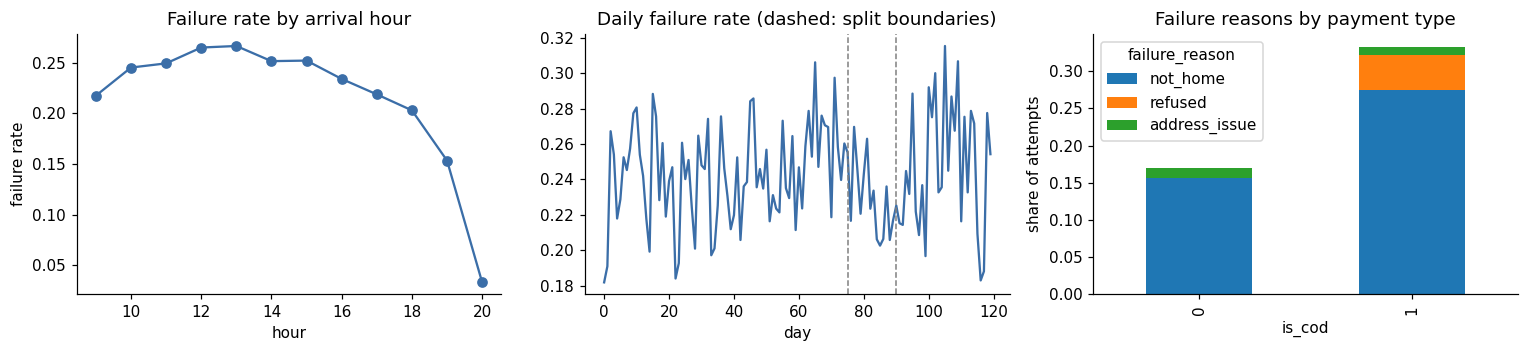

In [23]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

D = "data"
nodes = pd.read_csv(f"{D}/road_nodes.csv")
edges = pd.read_csv(f"{D}/road_edges.csv")
hub = pd.read_csv(f"{D}/hub.csv").iloc[0]
customers = pd.read_csv(f"{D}/customers.csv")
weather = pd.read_csv(f"{D}/weather.csv")
riders = pd.read_csv(f"{D}/riders.csv")
attempts = pd.read_csv(f"{D}/delivery_attempts.csv")
manifests = pd.read_csv(f"{D}/manifests.csv")
gps = pd.read_csv(f"{D}/gps_traversals.csv")

day_of = {d: i for i, d in enumerate(weather.date)}
for df in (attempts, manifests, gps):
    df["day"] = df.date.map(day_of)
for df in (attempts, manifests):
    df["requested_slot"] = df.requested_slot.fillna("")
attempts["failed"] = (attempts.outcome == "failed").astype(int)
cust_node = dict(zip(customers.customer_id, customers.node_id))
HUB_NODE = int(hub.node_id)
N_DAYS = len(weather)
TRAIN_END, VAL_END = 75, 90            # train: days 0-74, validation: 75-89, test: 90-119
split = lambda d: np.where(d < TRAIN_END, "train", np.where(d < VAL_END, "val", "test"))
attempts["split"] = split(attempts.day)

print(f"road network: {len(nodes):,} nodes, {len(edges):,} directed edges")
print(f"customers: {len(customers):,} | days: {N_DAYS} | attempts: {len(attempts):,} | GPS traversals: {len(gps):,}")
fa = attempts[attempts.attempt_no == 1]
print(f"first-attempt failure rate: {fa.failed.mean():.3f}")
print(attempts.failure_reason.value_counts().to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
h = attempts.arrival_hour.astype(int)
attempts.groupby(h).failed.mean().plot(ax=ax[0], marker="o", color="#3b6ea8")
ax[0].set(title="Failure rate by arrival hour", xlabel="hour", ylabel="failure rate")
attempts.groupby(attempts.day).failed.mean().plot(ax=ax[1], color="#3b6ea8")
for x in (TRAIN_END, VAL_END):
    ax[1].axvline(x, color="grey", ls="--", lw=1)
ax[1].set(title="Daily failure rate (dashed: split boundaries)", xlabel="day")
pd.crosstab(attempts.is_cod, attempts.failure_reason.fillna("delivered"), normalize="index")[["not_home", "refused", "address_issue"]].plot.bar(ax=ax[2], stacked=True)
ax[2].set(title="Failure reasons by payment type", xlabel="is_cod", ylabel="share of attempts")
plt.tight_layout(); plt.show()

### Leak-free history features
For a parcel on day *d*, history features use only attempts on days **before** *d* (as-of join). Rates are smoothed towards the training base rate so new customers are not given 0 or 1. The not-home rate is kept separately for three bands (morning 09–12, afternoon 12–16, evening 16–20); this is what lets even a linear model produce a customer-specific time-of-day curve.

In [24]:
BANDS = np.array([0, 1, 2])
band_of = lambda h: np.where(np.asarray(h) < 12, 0, np.where(np.asarray(h) < 16, 1, 2))
SLOT_RANGE = dict(morning=(9.0, 12.0), afternoon=(12.0, 16.0), evening=(16.0, 20.0))

A = attempts.copy()
A["band"] = band_of(A.arrival_hour)
A["nh"] = (A.failure_reason == "not_home").astype(int)
A["ref"] = (A.failure_reason == "refused").astype(int)
A["addr"] = (A.failure_reason == "address_issue").astype(int)
A["wkend"] = (weather.dow.values[A.day] >= 5).astype(int)
for k_, s_ in enumerate(("morning", "afternoon", "evening")):     # slots the customer asked for before
    A[f"req_b{k_}"] = (A.requested_slot == s_).astype(int)
for b in BANDS:
    A[f"att_b{b}"] = (A.band == b).astype(int)
    A[f"nh_b{b}"] = ((A.band == b) & (A.nh == 1)).astype(int)
    for w_ in (0, 1):                     # split by weekday / weekend
        A[f"att_b{b}_w{w_}"] = ((A.band == b) & (A.wkend == w_)).astype(int)
        A[f"nh_b{b}_w{w_}"] = ((A.band == b) & (A.wkend == w_) & (A.nh == 1)).astype(int)
agg_cols = ["failed", "nh", "ref", "addr", "delivered_to_security", "is_cod"] + \
           [f"att_b{b}" for b in BANDS] + [f"nh_b{b}" for b in BANDS] + \
           [f"{p}_b{b}_w{w_}" for p in ("att", "nh") for b in BANDS for w_ in (0, 1)] + \
           [f"req_b{b}" for b in BANDS]
per_day = A.groupby(["customer_id", "day"])[agg_cols].sum()
per_day["n"] = A.groupby(["customer_id", "day"]).size()
cum = per_day.groupby(level=0).cumsum().reset_index().sort_values("day")
cum = cum.rename(columns={c: "cum_" + c for c in agg_cols + ["n"]})
cum["last_day"] = cum.day

trainA = A[A.split == "train"]
G_FAIL = trainA.failed.mean()
G_NH_B = [trainA[trainA.band == b].nh.mean() for b in BANDS]
G_REF = trainA[trainA.is_cod == 1].ref.mean()
PRIOR = 3.0


def history_features(rows):
    """rows: DataFrame with customer_id, day (+ any other columns). Returns rows + history features
    computed from attempts strictly before `day`."""
    r = rows.reset_index(drop=True).copy()
    r["_i"] = np.arange(len(r))
    left = r[["_i", "customer_id", "day"]].sort_values("day")
    m = pd.merge_asof(left, cum, on="day", by="customer_id", allow_exact_matches=False)
    m = m.sort_values("_i").reset_index(drop=True)
    n = m.cum_n.fillna(0).values
    f = pd.DataFrame(index=r.index)
    f["prev_attempts"] = n
    f["prev_fails"] = m.cum_failed.fillna(0).values
    f["fail_rate_s"] = (f.prev_fails + PRIOR * G_FAIL) / (n + PRIOR)
    f["nh_rate_s"] = (m.cum_nh.fillna(0).values + PRIOR * G_FAIL) / (n + PRIOR)
    codn = m.cum_is_cod.fillna(0).values
    f["refuse_rate_s"] = (m.cum_ref.fillna(0).values + PRIOR * G_REF) / (codn + PRIOR)
    f["prev_addr_fail"] = m.cum_addr.fillna(0).values
    f["security_rate_s"] = (m.cum_delivered_to_security.fillna(0).values + 0.5) / (n + PRIOR)
    for b in BANDS:
        nb = m[f"cum_att_b{b}"].fillna(0).values
        f[f"att_b{b}"] = nb
        f[f"nh_rate_b{b}"] = (m[f"cum_nh_b{b}"].fillna(0).values + PRIOR * G_NH_B[b]) / (nb + PRIOR)
        for w_ in (0, 1):   # weekday/weekend version, shrunk towards the customer's band rate
            nbw = m[f"cum_att_b{b}_w{w_}"].fillna(0).values
            f[f"nh_rate_b{b}_w{w_}"] = (m[f"cum_nh_b{b}_w{w_}"].fillna(0).values + 2 * f[f"nh_rate_b{b}"]) / (nbw + 2)
    for b in BANDS:
        f[f"hist_req_b{b}"] = m[f"cum_req_b{b}"].fillna(0).values
    f["days_since_last"] = np.where(n > 0, r.day.values - m.last_day.fillna(0).values, 60).clip(0, 60)
    f["is_new_customer"] = (n == 0).astype(int)
    return pd.concat([r.drop(columns="_i"), f], axis=1)


cinfo = customers.set_index("customer_id")


def static_features(rows):
    """Parcel / customer / day context features (no arrival time yet)."""
    r = history_features(rows)
    r["is_apartment"] = (r.customer_id.map(cinfo.address_type) == "apartment").astype(int).values
    r["has_landmark"] = r.customer_id.map(cinfo.has_landmark).astype(int).values
    r["log_value"] = np.log(r.order_value_inr)
    for s in ("morning", "afternoon", "evening"):
        r[f"req_{s}"] = (r.requested_slot == s).astype(int)
    r["dow"] = weather.dow.values[r.day]
    r["is_weekend"] = (r.dow >= 5).astype(int)
    r["rain_day"] = weather.rain_day.values[r.day]
    r["rain_evening"] = weather.rain_evening.values[r.day]
    return r


def add_time_features(r, hour):
    """Attach arrival-time features; `hour` is an array aligned with r."""
    r = r.copy()
    hour = np.asarray(hour, float)
    r["arrival_hour"] = hour
    b = band_of(hour)
    for k in BANDS:
        r[f"band_{k}"] = (b == k).astype(int)
    nh_rates = r[[f"nh_rate_b{k}" for k in BANDS]].values
    r["nh_rate_cur"] = nh_rates[np.arange(len(r)), b]
    nh_dw = np.stack([r[[f"nh_rate_b{k}_w{w_}" for k in BANDS]].values for w_ in (0, 1)], 1)   # (n, 2, 3)
    r["nh_rate_cur_dw"] = nh_dw[np.arange(len(r)), r.is_weekend.values.astype(int), b]
    req_hist = r[[f"hist_req_b{k}" for k in BANDS]].values
    r["hist_req_cur"] = req_hist[np.arange(len(r)), b]
    r["hist_req_other"] = req_hist.sum(1) - r.hist_req_cur
    r["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    r["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    r["rain_now"] = ((r.rain_day == 1) & ((r.rain_evening == 0) | (hour >= 16))).astype(int)
    in_slot = np.zeros(len(r), bool)
    for s, (a, bb) in SLOT_RANGE.items():
        in_slot |= (r.requested_slot.values == s) & (hour >= a) & (hour < bb)
    r["in_requested_slot"] = in_slot.astype(int)
    # interactions that let a linear model bend its curve by segment
    for k in BANDS:
        r[f"band{k}_x_weekend"] = r[f"band_{k}"] * r.is_weekend
        r[f"band{k}_x_apartment"] = r[f"band_{k}"] * r.is_apartment
        r[f"band{k}_x_cod"] = r[f"band_{k}"] * r.is_cod
        r[f"band{k}_x_nhrate"] = r[f"band_{k}"] * r[f"nh_rate_b{k}"]
    return r


FEATURES = (["is_cod", "log_value", "weight_kg", "order_age_days", "attempt_no",
             "req_morning", "req_afternoon", "req_evening", "is_apartment", "has_landmark",
             "dow", "is_weekend", "rain_day", "rain_evening",
             "prev_attempts", "prev_fails", "fail_rate_s", "nh_rate_s", "refuse_rate_s",
             "prev_addr_fail", "security_rate_s", "days_since_last", "is_new_customer"]
            + [f"att_b{k}" for k in BANDS] + [f"nh_rate_b{k}" for k in BANDS]
            + [f"nh_rate_b{k}_w{w_}" for k in BANDS for w_ in (0, 1)]
            + [f"hist_req_b{k}" for k in BANDS] + ["hist_req_cur", "hist_req_other"]
            + ["arrival_hour", "hour_sin", "hour_cos", "rain_now", "in_requested_slot", "nh_rate_cur", "nh_rate_cur_dw"]
            + [f"band_{k}" for k in BANDS]
            + [f"band{k}_x_{v}" for k in BANDS for v in ("weekend", "apartment", "cod", "nhrate")])

t0 = time.time()
base = static_features(attempts[["day", "customer_id", "parcel_id", "is_cod", "order_value_inr", "weight_kg",
                                 "order_age_days", "attempt_no", "requested_slot"]])
X_all = add_time_features(base, attempts.arrival_hour.values)
y_all = attempts.failed.values
sp = attempts.split.values
print(f"features: {len(FEATURES)} | rows: {len(X_all):,} | built in {time.time()-t0:.1f}s")
print(pd.Series(sp).value_counts().to_string())

features: 62 | rows: 28,924 | built in 0.2s
train    18035
test      7177
val       3712


## 3. Failure-risk models: P(fail | parcel, arrival time τ)
Target: the first-attempt outcome failed for any reason (nobody home, COD refused, address problem). Three models on the same features and temporal split:
* **Logistic regression** – interpretable baseline (curve shape comes from band dummies × history rates).
* **XGBoost** – gradient-boosted trees.
* **FailNet (deep)** – a GRU encodes the customer's sequence of past attempts (time of day, outcome, reason); its embedding is combined with the tabular features and the arrival time in an MLP.

The model with the best **validation** log-loss feeds the optimiser. Test metrics are reported once.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
import xgboost as xgb

Xtr, ytr = X_all.loc[sp == "train", FEATURES].values, y_all[sp == "train"]
Xva, yva = X_all.loc[sp == "val", FEATURES].values, y_all[sp == "val"]
Xte, yte = X_all.loc[sp == "test", FEATURES].values, y_all[sp == "test"]

lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000))
lr.fit(Xtr, ytr)

xgbm = xgb.XGBClassifier(n_estimators=1500, max_depth=5, learning_rate=0.03, subsample=0.8,
                         colsample_bytree=0.8, min_child_weight=5, reg_lambda=2.0,
                         eval_metric="logloss", early_stopping_rounds=100, random_state=SEED,
                         n_jobs=-1)
xgbm.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
print("XGBoost best iteration:", xgbm.best_iteration)

XGBoost best iteration: 200


In [26]:
import torch, torch.nn as nn
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEQ_LEN = 12

# per-customer chronological attempt history (for the GRU)
A_sorted = A.sort_values(["customer_id", "day", "arrival_hour"])
SEQ_FEATS = np.c_[
    np.sin(2 * np.pi * A_sorted.arrival_hour / 24), np.cos(2 * np.pi * A_sorted.arrival_hour / 24),
    np.eye(3)[A_sorted.band.values],
    (weather.dow.values[A_sorted.day] >= 5).astype(float),
    A_sorted.is_cod.values, A_sorted.failed.values, A_sorted.nh.values, A_sorted.ref.values,
    A_sorted.addr.values, A_sorted.delivered_to_security.values,
].astype(np.float32)
SEQ_DIM = SEQ_FEATS.shape[1] + 1          # + recency
cust_rows = {}
for cid, idx in A_sorted.groupby("customer_id").indices.items():
    cust_rows[cid] = (A_sorted.day.values[idx], idx)


def build_sequences(rows):
    """(n, SEQ_LEN, SEQ_DIM) padded history strictly before each row's day, plus lengths."""
    out = np.zeros((len(rows), SEQ_LEN, SEQ_DIM), np.float32)
    lens = np.zeros(len(rows), np.int64)
    for i, (cid, d) in enumerate(zip(rows.customer_id.values, rows.day.values)):
        if cid not in cust_rows:
            continue
        days, idx = cust_rows[cid]
        k = np.searchsorted(days, d, side="left")
        if k == 0:
            continue
        sel = idx[max(0, k - SEQ_LEN):k]
        L = len(sel)
        out[i, :L, :-1] = SEQ_FEATS[sel]
        out[i, :L, -1] = np.minimum(d - days[max(0, k - SEQ_LEN):k], 60) / 60.0
        lens[i] = L
    return out, lens


class FailNet(nn.Module):
    def __init__(self, n_tab, seq_dim, hid=48):
        super().__init__()
        self.gru = nn.GRU(seq_dim, hid, batch_first=True)
        self.empty = nn.Parameter(torch.zeros(hid))
        self.mlp = nn.Sequential(nn.Linear(n_tab + hid, 128), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))

    def encode(self, seq, lens):
        h = self.empty.expand(len(seq), -1).clone()
        nz = lens > 0
        if nz.any():
            packed = nn.utils.rnn.pack_padded_sequence(seq[nz], lens[nz].cpu(), batch_first=True,
                                                       enforce_sorted=False)
            _, hn = self.gru(packed)
            h[nz] = hn[-1]
        return h

    def forward(self, tab, seq, lens, h=None):
        if h is None:
            h = self.encode(seq, lens)
        return self.mlp(torch.cat([tab, h], 1)).squeeze(1)


scaler_nn = StandardScaler().fit(Xtr)
seq_all, len_all = build_sequences(attempts)
T = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)


def nn_tensors(mask):
    return (T(scaler_nn.transform(X_all.loc[mask, FEATURES].values)), T(seq_all[mask]),
            torch.tensor(len_all[mask], device=DEVICE), T(y_all[mask]))


tr_t, va_t, te_t = nn_tensors(sp == "train"), nn_tensors(sp == "val"), nn_tensors(sp == "test")
failnet = FailNet(len(FEATURES), SEQ_DIM).to(DEVICE)
opt = torch.optim.AdamW(failnet.parameters(), lr=2e-3, weight_decay=1e-4)
lossf = nn.BCEWithLogitsLoss()
best, best_state, patience = 1e9, None, 0
for ep in range(40):
    failnet.train()
    perm = torch.randperm(len(tr_t[3]), device=DEVICE)
    for s in range(0, len(perm), 512):
        b = perm[s:s + 512]
        opt.zero_grad()
        loss = lossf(failnet(tr_t[0][b], tr_t[1][b], tr_t[2][b]), tr_t[3][b])
        loss.backward(); opt.step()
    failnet.eval()
    with torch.no_grad():
        vl = lossf(failnet(*va_t[:3]), va_t[3]).item()
    if vl < best - 1e-4:
        best, best_state, patience = vl, {k: v.clone() for k, v in failnet.state_dict().items()}, 0
    else:
        patience += 1
        if patience >= 5:
            break
failnet.load_state_dict(best_state); failnet.eval()
print(f"FailNet stopped after {ep+1} epochs, best val log-loss {best:.4f}")

FailNet stopped after 8 epochs, best val log-loss 0.4863


In [27]:
def predict_nn(tab_raw, seq, lens):
    with torch.no_grad():
        return torch.sigmoid(failnet(T(scaler_nn.transform(tab_raw)), T(seq),
                                     torch.tensor(lens, device=DEVICE))).cpu().numpy()


PRED = {
    "Logistic regression": lambda m: lr.predict_proba(X_all.loc[m, FEATURES].values)[:, 1],
    "XGBoost": lambda m: xgbm.predict_proba(X_all.loc[m, FEATURES].values)[:, 1],
    "FailNet (GRU)": lambda m: predict_nn(X_all.loc[m, FEATURES].values, seq_all[m], len_all[m]),
}


def topk_capture(y, p, frac):
    k = int(len(p) * frac)
    return y[np.argsort(-p)[:k]].sum() / y.sum()


rows = []
preds_test = {}
for name, f in PRED.items():
    pv, pt = f(sp == "val"), f(sp == "test")
    preds_test[name] = pt
    rows.append(dict(model=name, val_logloss=log_loss(yva, pv), test_logloss=log_loss(yte, pt),
                     test_ROC_AUC=roc_auc_score(yte, pt), test_PR_AUC=average_precision_score(yte, pt),
                     test_Brier=brier_score_loss(yte, pt),
                     capture_top10=topk_capture(yte, pt, 0.10), capture_top20=topk_capture(yte, pt, 0.20)))
base_p = np.full(len(yte), ytr.mean())
rows.append(dict(model="Base rate (no model)", val_logloss=log_loss(yva, np.full(len(yva), ytr.mean())),
                 test_logloss=log_loss(yte, base_p), test_ROC_AUC=0.5, test_PR_AUC=yte.mean(),
                 test_Brier=brier_score_loss(yte, base_p), capture_top10=0.10, capture_top20=0.20))
fail_metrics = pd.DataFrame(rows).set_index("model")
BEST_FAIL = fail_metrics.drop("Base rate (no model)").val_logloss.idxmin()
print("Selected by validation log-loss:", BEST_FAIL)
print(fail_metrics.round(4).to_string())

Selected by validation log-loss: FailNet (GRU)
                      val_logloss  test_logloss  test_ROC_AUC  test_PR_AUC  test_Brier  capture_top10  capture_top20
model                                                                                                               
Logistic regression        0.4954        0.5159        0.6949       0.4001      0.1714         0.1854         0.3262
XGBoost                    0.4864        0.5044        0.7065       0.4194      0.1675         0.1972         0.3482
FailNet (GRU)              0.4863        0.5055        0.7076       0.4155      0.1681         0.1938         0.3465
Base rate (no model)       0.5401        0.5594        0.5000       0.2473      0.1862         0.1000         0.2000


**Reading the table.** PR-AUC is compared with the base rate (the PR-AUC of a random ranking). `capture_top10` = share of all test failures that fall in the 10% of attempts the model ranks riskiest. Brier and log-loss measure calibration as well as ranking; calibration matters because the optimiser multiplies these probabilities by rupees.

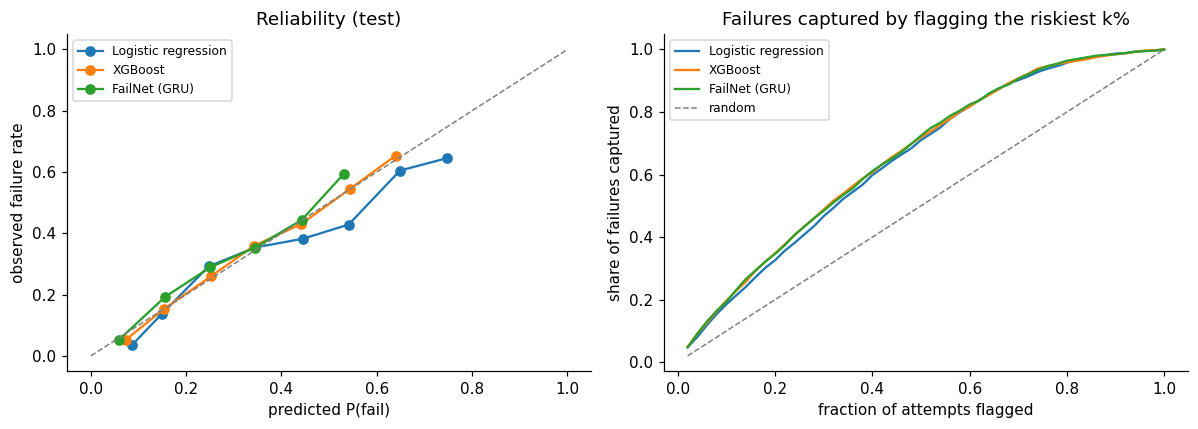

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 1, 11)
for name, pt in preds_test.items():
    idx = np.digitize(pt, bins) - 1
    xs = [pt[idx == k].mean() for k in range(10) if (idx == k).sum() >= 30]
    ys = [yte[idx == k].mean() for k in range(10) if (idx == k).sum() >= 30]
    ax[0].plot(xs, ys, marker="o", label=name)
ax[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
ax[0].set(title="Reliability (test)", xlabel="predicted P(fail)", ylabel="observed failure rate")
ax[0].legend(fontsize=8)
fracs = np.linspace(0.02, 1, 50)
for name, pt in preds_test.items():
    ax[1].plot(fracs, [topk_capture(yte, pt, f) for f in fracs], label=name)
ax[1].plot(fracs, fracs, color="grey", ls="--", lw=1, label="random")
ax[1].set(title="Failures captured by flagging the riskiest k%", xlabel="fraction of attempts flagged",
          ylabel="share of failures captured")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### The risk curve the optimiser uses
For each parcel we evaluate the selected model on a grid of arrival times (09:00–21:00, every 15 min). The optimiser reads this curve: the parcel's failure risk depends on **when** it is reached.

**[synthetic-only diagnostic]** Because the world is simulated, we can compare each predicted curve with the true one. This is not something a real deployment could measure; it is reported to show what the model has and has not learnt.

[synthetic-only] ceiling with true probabilities: test log-loss 0.4556, ROC-AUC 0.788, PR-AUC 0.523
Ranking quality by customer history (prior attempts):
         test attempts  ROC-AUC FailNet (GRU)  ROC-AUC true P (ceiling)*
new (0)            371                  0.640                      0.796
1-2               1022                  0.711                      0.798
3-5               1481                  0.676                      0.778
6+                4303                  0.720                      0.788
[synthetic-only] mean |predicted − true| failure probability over the 09–21h curve:
   Logistic regression    0.109
   XGBoost                0.100
   FailNet (GRU)          0.098


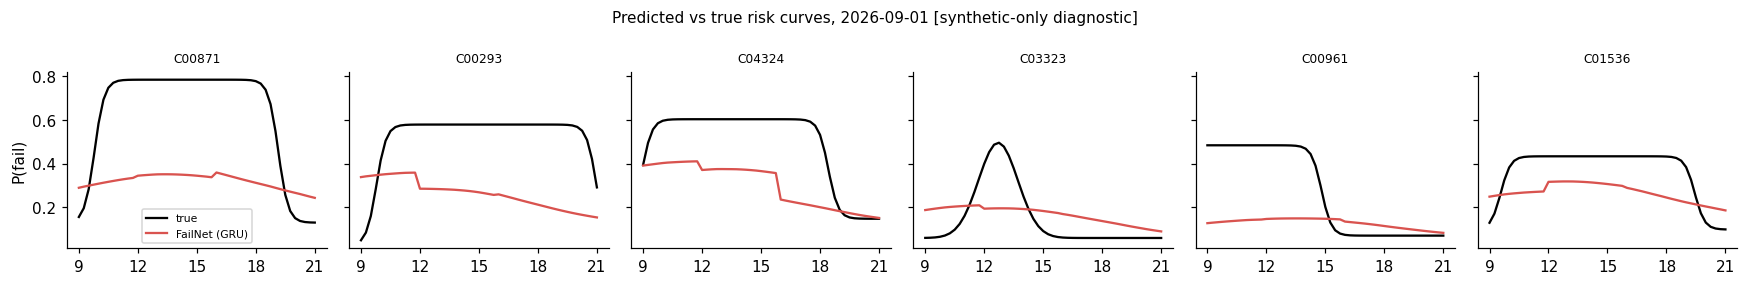

In [29]:
HOUR_GRID = np.round(np.arange(9.0, 21.01, 0.25), 2)


def risk_curves(manifest_rows, model=None):
    """(n_parcels, len(HOUR_GRID)) predicted P(fail) for each parcel at each arrival time."""
    model = model or BEST_FAIL
    b = static_features(manifest_rows[["day", "customer_id", "parcel_id", "is_cod", "order_value_inr",
                                       "weight_kg", "order_age_days", "attempt_no", "requested_slot"]])
    n, H = len(b), len(HOUR_GRID)
    big = add_time_features(b.loc[np.repeat(np.arange(n), H)].reset_index(drop=True), np.tile(HOUR_GRID, n))
    Xb = big[FEATURES].values
    if model == "Logistic regression":
        p = lr.predict_proba(Xb)[:, 1]
    elif model == "XGBoost":
        p = xgbm.predict_proba(Xb)[:, 1]
    else:
        seq, lens = build_sequences(manifest_rows)
        with torch.no_grad():
            h = failnet.encode(T(seq), torch.tensor(lens, device=DEVICE))
            h = h.repeat_interleave(H, 0)
            p = torch.sigmoid(failnet(T(scaler_nn.transform(Xb)), None, None, h=h)).cpu().numpy()
    return p.reshape(n, H)


world = SIM.load_world("ground_truth")          # hidden truth: diagnostics + plan scoring only
truth_man = pd.read_csv("ground_truth/manifests_with_draws.csv")
truth_man["requested_slot"] = truth_man.requested_slot.fillna("")

test_days = sorted(attempts.loc[sp == "test", "day"].unique())
curve_err = {m: [] for m in PRED}
for d in test_days[::3]:
    rows_d = manifests[manifests.day == d].reset_index(drop=True)
    true_c = world.true_fail_curve(rows_d, HOUR_GRID, d)
    for m in PRED:
        curve_err[m].append(np.abs(risk_curves(rows_d, m) - true_c).mean())
# best achievable: the TRUE probability at each test attempt's actual arrival time
p_true = np.zeros(int((sp == "test").sum()))
te_rows = attempts[sp == "test"].reset_index(drop=True)
for d, g in te_rows.groupby("day"):
    c = world.true_fail_curve(g, HOUR_GRID, d)
    hi = np.clip(np.round((g.arrival_hour.values - 9) / 0.25).astype(int), 0, len(HOUR_GRID) - 1)
    p_true[g.index] = c[np.arange(len(g)), hi]
print(f"[synthetic-only] ceiling with true probabilities: test log-loss {log_loss(yte, p_true):.4f}, "
      f"ROC-AUC {roc_auc_score(yte, p_true):.3f}, PR-AUC {average_precision_score(yte, p_true):.3f}")
# how much does history help? ranking quality by number of prior attempts for the customer
prior = X_all.loc[sp == "test", "prev_attempts"].values
buckets = pd.cut(prior, [-1, 0, 2, 5, 1000], labels=["new (0)", "1-2", "3-5", "6+"])
by_hist = pd.DataFrame({
    "test attempts": pd.Series(buckets).value_counts().sort_index(),
    f"ROC-AUC {BEST_FAIL}": [roc_auc_score(yte[buckets == b], preds_test[BEST_FAIL][buckets == b]) for b in buckets.categories],
    "ROC-AUC true P (ceiling)*": [roc_auc_score(yte[buckets == b], p_true[buckets == b]) for b in buckets.categories]},
    index=buckets.categories)
print("Ranking quality by customer history (prior attempts):")
print(by_hist.round(3).to_string())
print("[synthetic-only] mean |predicted − true| failure probability over the 09–21h curve:")
for m, v in curve_err.items():
    print(f"   {m:22s} {np.mean(v):.3f}")

d_ex = test_days[2]
rows_ex = manifests[manifests.day == d_ex].reset_index(drop=True)
pc, tc = risk_curves(rows_ex), world.true_fail_curve(rows_ex, HOUR_GRID, d_ex)
pick = np.argsort(-(tc.max(1) - tc.min(1)))[[0, 3, 8, 15, 30, 60]]
fig, axs = plt.subplots(1, 6, figsize=(16, 2.6), sharey=True)
for a_, i in zip(axs, pick):
    a_.plot(HOUR_GRID, tc[i], color="black", lw=1.5, label="true")
    a_.plot(HOUR_GRID, pc[i], color="#d9534f", lw=1.5, label=BEST_FAIL)
    a_.set_title(rows_ex.customer_id[i], fontsize=8); a_.set_xticks([9, 12, 15, 18, 21])
axs[0].set_ylabel("P(fail)"); axs[0].legend(fontsize=7)
plt.suptitle(f"Predicted vs true risk curves, {weather.date[d_ex]} [synthetic-only diagnostic]", fontsize=10)
plt.tight_layout(); plt.show()

## 4. Road network as a graph
Nodes are OSM intersections, edges are directed road segments. Free-flow time = length / typical speed for the road class. The courier's own rider GPS gives observed traversal times on the roads riders actually drove.

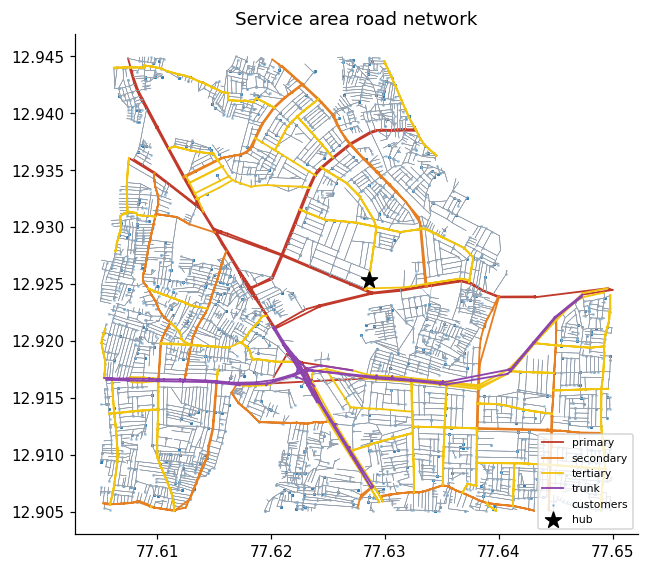

In [30]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

NN, NE = len(nodes), len(edges)
EU, EV = edges.u.values, edges.v.values
FF_TIME = (edges.length_m / (edges.speed_limit_kmph / 3.6)).values          # seconds
N_SLOTS, FIRST_HOUR = 12, 9
slot_of = lambda h: np.clip(np.floor(np.asarray(h, float)).astype(int) - FIRST_HOUR, 0, N_SLOTS - 1)


def sp_matrix(w, node_list, chunk=400):
    """shortest-path matrix among node_list under edge weights w"""
    Ad = csr_matrix((np.asarray(w, float), (EU, EV)), shape=(NN, NN))
    node_list = np.asarray(node_list)
    out = np.empty((len(node_list), len(node_list)), np.float32)
    for s in range(0, len(node_list), chunk):
        out[s:s + chunk] = dijkstra(Ad, indices=node_list[s:s + chunk])[:, node_list]
    return out


def rain_now(day, hour):
    w = weather.iloc[day]
    return int(w.rain_day == 1 and (w.rain_evening == 0 or hour >= 16))


fig, ax = plt.subplots(figsize=(6, 5.5))
hw_col = {"primary": "#c0392b", "secondary": "#e67e22", "tertiary": "#f1c40f", "trunk": "#8e44ad"}
for hwy, g in edges.groupby("highway"):
    xs = np.c_[nodes.lon.values[g.u], nodes.lon.values[g.v], np.full(len(g), np.nan)].ravel()
    ys = np.c_[nodes.lat.values[g.u], nodes.lat.values[g.v], np.full(len(g), np.nan)].ravel()
    ax.plot(xs, ys, color=hw_col.get(hwy, "#9aa5b1"), lw=1.2 if hwy in hw_col else 0.4,
            label=hwy if hwy in hw_col else None)
ax.scatter(customers.lon, customers.lat, s=1, color="#2c7fb8", alpha=0.3, label="customers")
ax.scatter([hub.lon], [hub.lat], s=120, marker="*", color="black", label="hub", zorder=5)
ax.set_title("Service area road network"); ax.legend(fontsize=7, loc="lower right"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

## 5. Travel-time prediction: GNN vs baselines
Target: log(observed traversal time / free-flow time) for an edge at a given hour, day of week and rain state. **15% of edges are held out completely** (never seen in training) to test whether the model generalises to roads with no GPS history.

Models: **free-flow** (no congestion), **road-class table** (mean by class × hour × weekend × rain), **MLP** (same edge + context features, no graph), **GNN** (3 message-passing layers over the road graph, then an edge head). The GNN is written in plain PyTorch (no extra library).

In [31]:
HWY = sorted(edges.highway.unique())
rng_np = np.random.default_rng(SEED)
unseen_edge = np.zeros(NE, bool)
unseen_edge[rng_np.choice(NE, int(0.15 * NE), replace=False)] = True

g_ = gps.copy()
g_["slot"] = slot_of(g_.entry_hour)
g_["y"] = np.log(g_.travel_time_s / FF_TIME[g_.edge_id])
g_["dow"] = weather.dow.values[g_.day]
g_["weekend"] = (g_.dow >= 5).astype(int)
g_["rain_now"] = ((weather.rain_day.values[g_.day] == 1) &
                  ((weather.rain_evening.values[g_.day] == 0) | (g_.entry_hour >= 16))).astype(int)
g_["split"] = split(g_.day)
g_["unseen"] = unseen_edge[g_.edge_id]
gtr = g_[(g_.split == "train") & ~g_.unseen]
gva = g_[(g_.split == "val") & ~g_.unseen]
gte = g_[g_.split == "test"]
print(f"GPS rows  train {len(gtr):,} | val {len(gva):,} | test {len(gte):,} "
      f"(test on held-out edges: {gte.unseen.sum():,})")
print(f"edges with any training GPS: {gtr.edge_id.nunique():,} of {NE:,}")

# --- node and edge features (observable only)
deg_out = np.bincount(EU, minlength=NN); deg_in = np.bincount(EV, minlength=NN)
hub_d = np.hypot((nodes.lat - hub.lat) * 111.3, (nodes.lon - hub.lon) * 108.6).values
node_x = np.c_[(nodes.lat - nodes.lat.mean()) / nodes.lat.std(), (nodes.lon - nodes.lon.mean()) / nodes.lon.std(),
               deg_in / 4, deg_out / 4, hub_d / 3].astype(np.float32)
edge_x = np.c_[np.log(edges.length_m) - 4, np.eye(len(HWY))[edges.highway.map({h: i for i, h in enumerate(HWY)})],
               edges.lanes / 2, edges.oneway.astype(float), edges.speed_limit_kmph / 30].astype(np.float32)


def ctx_matrix(slot, dow, rain):
    slot, dow, rain = np.asarray(slot), np.asarray(dow), np.asarray(rain)
    return np.c_[np.eye(N_SLOTS)[slot], np.eye(7)[dow], (dow >= 5), rain].astype(np.float32)


CTX_DIM = N_SLOTS + 7 + 2
tN, tE = T(node_x), T(edge_x)
tsrc = torch.tensor(EU, device=DEVICE); tdst = torch.tensor(EV, device=DEVICE)
din = T(np.maximum(deg_in, 1))[:, None]; dout = T(np.maximum(deg_out, 1))[:, None]


class MPLayer(nn.Module):
    def __init__(self, h, e):
        super().__init__()
        self.m_in = nn.Sequential(nn.Linear(h + e, h), nn.ReLU())
        self.m_out = nn.Sequential(nn.Linear(h + e, h), nn.ReLU())
        self.upd = nn.Sequential(nn.Linear(3 * h, h), nn.ReLU())
        self.norm = nn.LayerNorm(h)

    def forward(self, h, ef):
        a_in = torch.zeros_like(h).index_add_(0, tdst, self.m_in(torch.cat([h[tsrc], ef], 1))) / din
        a_out = torch.zeros_like(h).index_add_(0, tsrc, self.m_out(torch.cat([h[tdst], ef], 1))) / dout
        return self.norm(h + self.upd(torch.cat([h, a_in, a_out], 1)))


class TravelGNN(nn.Module):
    def __init__(self, hid=64, layers=3):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(node_x.shape[1], hid), nn.ReLU())
        self.layers = nn.ModuleList([MPLayer(hid, edge_x.shape[1]) for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(2 * hid + edge_x.shape[1] + CTX_DIM, 128), nn.ReLU(),
                                  nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))

    def embed(self):
        h = self.enc(tN)
        for L in self.layers:
            h = L(h, tE)
        return h

    def forward(self, eid, ctx, h=None):
        h = self.embed() if h is None else h
        return self.head(torch.cat([h[tsrc[eid]], h[tdst[eid]], tE[eid], ctx], 1)).squeeze(1)


class TravelMLP(nn.Module):
    """same inputs per edge (endpoint node features + edge features + context), no message passing"""
    def __init__(self):
        super().__init__()
        self.head = nn.Sequential(nn.Linear(2 * node_x.shape[1] + edge_x.shape[1] + CTX_DIM, 128), nn.ReLU(),
                                  nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))

    def embed(self):
        return tN

    def forward(self, eid, ctx, h=None):
        return self.head(torch.cat([tN[tsrc[eid]], tN[tdst[eid]], tE[eid], ctx], 1)).squeeze(1)


def tensors(g):
    return (torch.tensor(g.edge_id.values, device=DEVICE), T(ctx_matrix(g.slot, g.dow, g.rain_now)), T(g.y.values))


def train_tt(model, epochs=60, bs=4096, lr_=2e-3):
    opt_ = torch.optim.AdamW(model.parameters(), lr=lr_, weight_decay=1e-4)
    tr, va = tensors(gtr), tensors(gva)
    best_, state_, pat = 1e9, None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(tr[2]), device=DEVICE)
        for s in range(0, len(perm), bs):
            b = perm[s:s + bs]
            opt_.zero_grad()
            loss = nn.functional.huber_loss(model(tr[0][b], tr[1][b]), tr[2][b], delta=0.5)
            loss.backward(); opt_.step()
        model.eval()
        with torch.no_grad():
            vl = (model(va[0], va[1]) - va[2]).abs().mean().item()
        if vl < best_ - 1e-4:
            best_, state_, pat = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            pat += 1
            if pat >= 4:
                break
    model.load_state_dict(state_); model.eval()
    return model, best_, ep + 1


t0 = time.time()
torch.manual_seed(SEED)
gnn, gnn_val, gnn_ep = train_tt(TravelGNN().to(DEVICE))
print(f"GNN: val MAE(log) {gnn_val:.4f} after {gnn_ep} epochs ({time.time()-t0:.0f}s)")
t0 = time.time()
torch.manual_seed(SEED)
mlp_tt, mlp_val, mlp_ep = train_tt(TravelMLP().to(DEVICE))
print(f"MLP: val MAE(log) {mlp_val:.4f} after {mlp_ep} epochs ({time.time()-t0:.0f}s)")

# road-class table baseline
tab = gtr.assign(hw=edges.highway.values[gtr.edge_id]).groupby(["hw", "slot", "weekend", "rain_now"]).y.mean()
tab2 = gtr.assign(hw=edges.highway.values[gtr.edge_id]).groupby(["hw", "slot"]).y.mean()
g_mean = gtr.y.mean()


def table_pred(eid, slot, weekend, rain):
    hw = edges.highway.values[eid]
    out = np.full(len(eid), g_mean)
    k1 = list(zip(hw, slot, weekend, rain))
    v1 = tab.reindex(k1).values
    v2 = tab2.reindex(list(zip(hw, slot))).values
    out = np.where(np.isfinite(v2), v2, out)
    return np.where(np.isfinite(v1), v1, out)


def nn_pred(model, eid, ctx):
    with torch.no_grad():
        h = model.embed()
        out = []
        for s in range(0, len(eid), 200000):
            out.append(model(torch.tensor(eid[s:s + 200000], device=DEVICE), T(ctx[s:s + 200000]), h=h).cpu().numpy())
    return np.concatenate(out)


TT_MODELS = ["Free-flow", "Road-class table", "MLP (no graph)", "GNN"]


def predict_log_ratio(name, eid, slot, dow, rain):
    eid, slot, dow, rain = map(np.asarray, (eid, slot, dow, rain))
    if name == "Free-flow":
        return np.zeros(len(eid))
    if name == "Road-class table":
        return table_pred(eid, slot, (dow >= 5).astype(int), rain)
    model = gnn if name == "GNN" else mlp_tt
    return nn_pred(model, eid, ctx_matrix(slot, dow, rain))


rows = []
for name in TT_MODELS:
    p = predict_log_ratio(name, gte.edge_id.values, gte.slot.values, gte.dow.values, gte.rain_now.values)
    err_s = np.abs(np.exp(p) * FF_TIME[gte.edge_id] - gte.travel_time_s.values)
    err_l = np.abs(p - gte.y.values)
    rows.append({"model": name,
                 "MAE log-ratio (seen edges)": err_l[~gte.unseen.values].mean(),
                 "MAE log-ratio (held-out edges)": err_l[gte.unseen.values].mean(),
                 "MAE seconds/edge (all)": err_s.mean()})
tt_metrics = pd.DataFrame(rows).set_index("model")
print("Test-day GPS traversals (individual traversals include ~15% rider-level noise):")
print(tt_metrics.round(4).to_string())


def edge_times(name, day):
    """(N_SLOTS, NE) predicted edge traversal seconds for every slot of `day`."""
    dow = int(weather.dow.iloc[day])
    hours = FIRST_HOUR + np.arange(N_SLOTS)
    eid = np.tile(np.arange(NE), N_SLOTS)
    slot = np.repeat(np.arange(N_SLOTS), NE)
    rain = np.repeat([rain_now(day, h + 0.5) for h in hours], NE)
    p = predict_log_ratio(name, eid, slot, np.full(len(eid), dow), rain)
    return (np.exp(p).reshape(N_SLOTS, NE) * FF_TIME[None, :]).astype(np.float32)

GPS rows  train 138,168 | val 28,261 | test 65,170 (test on held-out edges: 10,042)
edges with any training GPS: 8,405 of 12,896
GNN: val MAE(log) 0.1499 after 35 epochs (219s)
MLP: val MAE(log) 0.1663 after 19 epochs (8s)
Test-day GPS traversals (individual traversals include ~15% rider-level noise):
                  MAE log-ratio (seen edges)  MAE log-ratio (held-out edges)  MAE seconds/edge (all)
model                                                                                               
Free-flow                             0.5581                          0.5678                  7.4631
Road-class table                      0.1886                          0.1933                  3.1779
MLP (no graph)                        0.1645                          0.1701                  2.7910
GNN                                   0.1502                          0.1794                  2.5750


### Stop-to-stop accuracy (what the optimiser actually consumes)
The optimiser needs **leg** times between consecutive stops, i.e. shortest paths over predicted edge times. Legs are taken from the test-day legacy routes; the true leg time comes from the simulator's true traffic **[synthetic-only diagnostic]**. The last column compares predicted with true congestion on **every** edge (including roads no rider drove).

In [32]:
legs = attempts[sp == "test"].sort_values(["day", "rider_id", "stop_seq"]).copy()
legs["from_node"] = legs.groupby(["day", "rider_id"]).customer_id.shift(1).map(cust_node)
legs["dep_hour"] = legs.groupby(["day", "rider_id"]).arrival_hour.shift(1) + \
    legs.groupby(["day", "rider_id"]).service_min.shift(1) / 60
legs["to_node"] = legs.customer_id.map(cust_node)
legs = legs.dropna(subset=["from_node"])
legs = legs[legs.from_node != legs.to_node]
legs = legs.sample(min(600, len(legs)), random_state=SEED)
legs["slot"] = slot_of(legs.dep_hour)

leg_rows = {m: [] for m in TT_MODELS}
true_leg, edge_err = [], {m: [] for m in TT_MODELS}
for d, gd in legs.groupby("day"):
    Ttrue = world.true_edge_times(d)
    Tp = {m: edge_times(m, d) for m in TT_MODELS}
    for m in TT_MODELS:
        edge_err[m].append(np.abs(Tp[m] / Ttrue - 1).mean())
    for s, gs in gd.groupby("slot"):
        src = gs.from_node.astype(int).values
        At = csr_matrix((Ttrue[s], (EU, EV)), shape=(NN, NN))
        dt = dijkstra(At, indices=np.unique(src))
        pos = {n: i for i, n in enumerate(np.unique(src))}
        true_leg += list(dt[[pos[x] for x in src], gs.to_node.astype(int).values])
        for m in TT_MODELS:
            Ap = csr_matrix((Tp[m][s], (EU, EV)), shape=(NN, NN))
            dp = dijkstra(Ap, indices=np.unique(src))
            leg_rows[m] += list(dp[[pos[x] for x in src], gs.to_node.astype(int).values])
true_leg = np.array(true_leg)
tt_metrics["leg MAPE vs truth*"] = [np.mean(np.abs(np.array(leg_rows[m]) - true_leg) / true_leg) for m in TT_MODELS]
tt_metrics["edge congestion MAPE, all edges*"] = [np.mean(edge_err[m]) for m in TT_MODELS]
print("* synthetic-only diagnostics")
print(tt_metrics.round(4).to_string())

* synthetic-only diagnostics
                  MAE log-ratio (seen edges)  MAE log-ratio (held-out edges)  MAE seconds/edge (all)  leg MAPE vs truth*  edge congestion MAPE, all edges*
model                                                                                                                                                     
Free-flow                             0.5581                          0.5678                  7.4631              0.3856                            0.3680
Road-class table                      0.1886                          0.1933                  3.1779              0.1157                            0.1634
MLP (no graph)                        0.1645                          0.1701                  2.7910              0.0755                            0.1163
GNN                                   0.1502                          0.1794                  2.5750              0.0656                            0.1067


## 6. Cost matrix for a delivery day
For tomorrow's parcels we build, for the hub and every stop:
* shortest **distance** matrix (km cost),
* **travel-time** matrices for each hour slot, from the GNN's predicted edge times (12 slots → time-dependent),
* each parcel's **risk curve** P(fail | τ) from the failure model, turned into rupees: `C_fail × P(fail | τ)`, plus the SLA penalty if τ falls outside a requested slot.

Cost parameters are business **assumptions** (listed below); the report should cite or justify each.

In [33]:
from ortools.constraint_solver import pywrapcp, routing_enums_pb2

COST = dict(SIM.CONFIG["cost"])
SHIFTS = list(zip(riders.shift_start_h, riders.shift_end_h))
K_RIDERS, CAP = len(riders), int(riders.capacity_parcels.iloc[0])
print("cost assumptions (INR):", COST)
print("rider shifts:", SHIFTS, "| capacity", CAP)

# planned service time per stop, estimated from history (train days)
_h = attempts[(sp == "train") & (attempts.outcome == "delivered")].copy()
_h["apt"] = (_h.customer_id.map(cinfo.address_type) == "apartment").astype(int)
SVC_TABLE = _h.groupby(["is_cod", "apt"]).service_min.mean()
print("planned service minutes by (COD, apartment):", SVC_TABLE.round(2).to_dict())


class DayProblem:
    def __init__(self, d):
        self.d = d
        self.man = manifests[manifests.day == d].reset_index(drop=True)
        self.n = len(self.man)
        self.stop_node = self.man.customer_id.map(cust_node).values.astype(int)
        self.node_list = np.unique(np.r_[HUB_NODE, self.stop_node])
        self.nidx = {nd: i for i, nd in enumerate(self.node_list)}
        self.M = np.r_[self.nidx[HUB_NODE], [self.nidx[x] for x in self.stop_node]]   # 0 = depot
        apt = (self.man.customer_id.map(cinfo.address_type) == "apartment").astype(int).values
        self.svc_s = 60 * np.r_[0.0, SVC_TABLE.reindex(list(zip(self.man.is_cod, apt))).values]
        self.D = sp_matrix(edges.length_m.values, self.node_list)
        self.T = {}
        self.curves = {}
        self.sla = np.zeros((self.n, len(HOUR_GRID)))
        for i, s in enumerate(self.man.requested_slot.values):
            if s:
                a, b = SLOT_RANGE[s]
                self.sla[i] = COST["per_sla_min"] * 60 * np.maximum(0, np.maximum(a - HOUR_GRID, HOUR_GRID - b))

    def times(self, source):
        if source not in self.T:
            if source == "ff":
                self.T[source] = np.repeat(sp_matrix(FF_TIME, self.node_list)[None], N_SLOTS, 0)
            elif source == "true":                       # oracle and scoring only
                Ts, _ = world.true_matrices(self.d, self.node_list)
                self.T[source] = Ts
            else:
                Te = edge_times(source, self.d)
                self.T[source] = np.stack([sp_matrix(Te[s], self.node_list) for s in range(N_SLOTS)])
        return self.T[source]

    def curve(self, source, perturb=None):
        key = (source, str(perturb))
        if key not in self.curves:
            if source == "model":
                self.curves[key] = risk_curves(self.man)
            else:                                        # 'true' -> oracle only
                self.curves[key] = world.true_fail_curve(self.man, HOUR_GRID, self.d, perturb)
        return self.curves[key]

cost assumptions (INR): {'per_km': 3.0, 'per_rider_min': 2.0, 'per_overtime_min': 4.0, 'per_failed_attempt': 90.0, 'per_deferral': 70.0, 'per_sla_min': 1.0}
rider shifts: [(9.0, 15.0), (9.0, 15.0), (12.0, 18.0), (12.0, 18.0), (14.5, 20.5), (14.5, 20.5)] | capacity 50
planned service minutes by (COD, apartment): {(0, 0): 3.05, (0, 1): 5.09, (1, 0): 4.57, (1, 1): 6.67}


## 7–8. Optimiser: OR-Tools VRP + local search
**Stage 1, OR-Tools.** Vehicle routing with rider shifts (time dimension, no idling), capacity, and per-parcel *soft time windows*. The rupee curve `g_i(τ) = C_fail·P(fail_i | τ) + SLA_i(τ)` is approximated by its low-cost window plus linear penalties on either side. Arc cost = km cost + rider-minute cost under the planner's travel-time source. If deferral is enabled, a parcel can be deferred to tomorrow at cost `C_defer`; this decision is made in stage 2.

**Stage 2, local search.** OR-Tools can't take an arbitrary curve or time-dependent travel times, so its plan is improved by relocate (including moving a parcel to an earlier or later rider shift), swap, 2-opt and, where enabled, defer / re-insert moves, scored with the exact objective: time-dependent travel times by departure slot, the full risk curve, overtime and SLA.

**Warm starts.** Each planner also receives the previous planner's plan as a second starting point and keeps whichever candidate is cheaper *under its own information*. This removes most solver noise from the comparison: a risk-aware planner can never do worse in its own estimate than simply re-using the time-aware plan. P3b starts only from P3a's plan, so P3a → P3b is exactly the value of the deferral option.

Every planner uses the same code; they differ only in the information they get.

In [34]:
PLANNERS = {   # warm: earlier planners whose plans are also offered as starting points
    "P1 Distance-only VRP":          dict(tt="ff",  risk=None,    defer=False, objective="distance", ortools=True,  warm=[]),
    "P2 Time-aware (GNN)":          dict(tt="GNN", risk=None,    defer=False, objective="cost",     ortools=True,  warm=["P1 Distance-only VRP"]),
    "P3a Risk-aware (sequencing)":  dict(tt="GNN", risk="model", defer=False, objective="cost",     ortools=True,  warm=["P2 Time-aware (GNN)"]),
    "P3b Risk-aware (+deferral)":   dict(tt="GNN", risk="model", defer=True,  objective="cost",     ortools=False, warm=["P3a Risk-aware (sequencing)"]),
    "P4 Oracle risk (true P(fail))": dict(tt="GNN", risk="true", defer=True,  objective="cost",     ortools=True,  warm=["P2 Time-aware (GNN)"]),
}
H0, HSTEP = HOUR_GRID[0], HOUR_GRID[1] - HOUR_GRID[0]


def soft_window(g):
    """low-cost window [a,b] (hours) and slopes (INR/hour) approximating curve g on HOUR_GRID"""
    j = int(np.argmin(g)); gmin = g[j]
    ok = g <= gmin + 4.0
    a = j
    while a > 0 and ok[a - 1]:
        a -= 1
    b = j
    while b < len(g) - 1 and ok[b + 1]:
        b += 1
    def secant(i0, i1):
        dh = abs(HOUR_GRID[i1] - HOUR_GRID[i0])
        return max(0.0, (g[i1] - g[i0]) / dh) if dh > 0 else 0.0
    lo_slope = secant(a, max(a - 8, 0)) if a > 0 else 0.0
    hi_slope = secant(b, min(b + 8, len(g) - 1)) if b < len(g) - 1 else 0.0
    return HOUR_GRID[a], HOUR_GRID[b], lo_slope, hi_slope, gmin


class RouteEval:
    """exact plan cost under a planner's information (time-dependent travel, full curves)"""
    def __init__(self, P, Tm, g, D, objective="cost"):
        self.distance_only = objective == "distance"
        self.M = P.M
        self.T = [Tm[s].tolist() for s in range(N_SLOTS)]
        self.D = D.tolist()
        self.svc = P.svc_s.tolist()
        self.g = np.vstack([np.zeros((1, g.shape[1])), g]).tolist() if g is not None else None
        self.H = len(HOUR_GRID)
        self.start = [3600 * (s + 10 / 60) for s, _ in SHIFTS]
        self.end = [3600 * e for _, e in SHIFTS]

    def gval(self, i, hour):
        x = (hour - H0) / HSTEP
        if x <= 0:
            return self.g[i][0]
        if x >= self.H - 1:
            return self.g[i][-1]
        k = int(x); f = x - k
        row = self.g[i]
        return row[k] * (1 - f) + row[k + 1] * f

    def route(self, k, r, detail=False):
        t = self.start[k]; prev = self.M[0]; km = 0.0; c = 0.0; arr = []
        for i in r:
            s = min(max(int(t // 3600) - FIRST_HOUR, 0), N_SLOTS - 1)
            mi = self.M[i]
            t += self.T[s][prev][mi]
            km += self.D[prev][mi]
            if self.g is not None:
                c += self.gval(i, t / 3600)
            if detail:
                arr.append(t / 3600)
            t += self.svc[i]
            prev = mi
        s = min(max(int(t // 3600) - FIRST_HOUR, 0), N_SLOTS - 1)
        t += self.T[s][prev][self.M[0]]
        km += self.D[prev][self.M[0]]
        if self.distance_only:
            return (c + COST["per_km"] * km / 1000, arr) if detail else c + COST["per_km"] * km / 1000
        c += COST["per_km"] * km / 1000 + COST["per_rider_min"] * (t - self.start[k]) / 60 \
            + COST["per_overtime_min"] * max(0.0, t - self.end[k]) / 60
        return (c, arr) if detail else c


def solve_ortools(P, cfg, Tm, g):
    n, N = P.n, P.n + 1
    Tavg = Tm.mean(0)[np.ix_(P.M, P.M)]
    Dm = P.D[np.ix_(P.M, P.M)]
    tmat = (Tavg + P.svc_s[:, None]).round().astype(int)
    if cfg["objective"] == "distance":
        cmat = (COST["per_km"] * Dm).round().astype(int)                       # milli-INR
    else:
        cmat = (COST["per_km"] * Dm + COST["per_rider_min"] * 1000 * Tavg / 60).round().astype(int)
    np.fill_diagonal(tmat, 0); np.fill_diagonal(cmat, 0)
    mgr = pywrapcp.RoutingIndexManager(N, K_RIDERS, 0)
    rt = pywrapcp.RoutingModel(mgr)
    try:
        tcb = rt.RegisterTransitMatrix(tmat.tolist())
        ccb = rt.RegisterTransitMatrix(cmat.tolist())
    except Exception:
        tl, cl = tmat.tolist(), cmat.tolist()
        tcb = rt.RegisterTransitCallback(lambda a, b: tl[mgr.IndexToNode(a)][mgr.IndexToNode(b)])
        ccb = rt.RegisterTransitCallback(lambda a, b: cl[mgr.IndexToNode(a)][mgr.IndexToNode(b)])
    rt.SetArcCostEvaluatorOfAllVehicles(ccb)
    rt.AddDimension(tcb, 0, 26 * 3600, False, "Time")
    td = rt.GetDimensionOrDie("Time")
    dcb = rt.RegisterUnaryTransitCallback(lambda a: 0 if mgr.IndexToNode(a) == 0 else 1)
    rt.AddDimensionWithVehicleCapacity(dcb, 0, [CAP] * K_RIDERS, True, "Cap")
    ot_coef = int(round(COST["per_overtime_min"] * 1000 / 60))
    for k, (s, e) in enumerate(SHIFTS):
        st = int(3600 * (s + 10 / 60))
        td.CumulVar(rt.Start(k)).SetRange(st, st)
        td.CumulVar(rt.End(k)).SetMax(int(3600 * (e + 3)))
        td.SetCumulVarSoftUpperBound(rt.End(k), int(3600 * e), ot_coef)
    for i in range(1, N):
        idx = mgr.NodeToIndex(i)
        gi = g[i - 1] if g is not None else np.zeros(len(HOUR_GRID))
        a, b, sl, sh, gmin = soft_window(gi)
        if sl > 0:
            td.SetCumulVarSoftLowerBound(idx, int(3600 * a), max(1, int(round(sl * 1000 / 3600))))
        if sh > 0:
            td.SetCumulVarSoftUpperBound(idx, int(3600 * b), max(1, int(round(sh * 1000 / 3600))))
        rt.AddDisjunction([idx], 10 ** 9)          # every parcel is routed here; deferral is decided in stage 2
    prm = pywrapcp.DefaultRoutingSearchParameters()
    prm.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PARALLEL_CHEAPEST_INSERTION
    prm.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    prm.time_limit.FromSeconds(SOLVER_SECONDS)
    sol = rt.SolveWithParameters(prm)
    if sol is None:
        raise RuntimeError("OR-Tools found no solution")
    routes = []
    for k in range(K_RIDERS):
        idx, r = rt.Start(k), []
        idx = sol.Value(rt.NextVar(idx))
        while not rt.IsEnd(idx):
            r.append(mgr.IndexToNode(idx)); idx = sol.Value(rt.NextVar(idx))
        routes.append(r)
    used = set(x for r in routes for x in r)
    dropped = [i for i in range(1, N) if i not in used]
    return routes, dropped


def local_search(P, cfg, ev, routes, dropped, seconds):
    """first-improvement local search on the exact objective.
    Moves: relocate (next to nearby stops, and into every other rider's route at the point nearest
    to the stop, so a parcel can switch to an earlier or later shift), swap between riders,
    2-opt within a route, and (if enabled) defer / re-insert."""
    t_end = time.time() + seconds
    rng_ = np.random.default_rng(P.d)
    Dm = P.D[np.ix_(P.M, P.M)]
    Dsym = np.minimum(Dm, Dm.T)
    near = np.argsort(Dsym[1:, 1:], 1)[:, 1:9] + 1                      # 8 nearest stops
    routes = [list(r) for r in routes]
    cost = [ev.route(k, r) for k, r in enumerate(routes)]
    where = {}

    def reindex():
        where.clear()
        for k, r in enumerate(routes):
            for p, i in enumerate(r):
                where[i] = (k, p)

    def candidates(i, k1):
        cs = [j for j in near[i - 1] if j in where]
        for k2, r in enumerate(routes):                                  # nearest stop in every other route
            if k2 != k1 and r:
                cs.append(r[int(np.argmin(Dsym[i, r]))])
        return cs

    reindex()
    dropped = list(dropped)
    improved = True
    while improved and time.time() < t_end:
        improved = False
        for i in rng_.permutation(np.arange(1, P.n + 1)):
            if time.time() > t_end:
                break
            if i not in where:
                continue
            k1, p1 = where[i]
            r1 = routes[k1][:p1] + routes[k1][p1 + 1:]
            c1 = ev.route(k1, r1)
            best = (1e-6, None)
            if cfg["defer"]:
                gain = cost[k1] - c1 - COST["per_deferral"]
                if gain > best[0]:
                    best = (gain, ("defer",))
            for j in candidates(i, k1):
                k2, p2 = where[j]
                for q in (p2, p2 + 1):                                   # relocate before / after j
                    if k2 == k1:
                        qq = q - (1 if p1 < q else 0)
                        cand = r1[:qq] + [i] + r1[qq:]
                        gain = cost[k1] - ev.route(k1, cand)
                        if gain > best[0]:
                            best = (gain, ("one", k1, cand))
                    elif len(routes[k2]) < CAP:
                        cand = routes[k2][:q] + [i] + routes[k2][q:]
                        gain = cost[k1] + cost[k2] - c1 - ev.route(k2, cand)
                        if gain > best[0]:
                            best = (gain, ("two", k1, r1, k2, cand))
                if k2 != k1:                                             # swap i and j
                    a1 = routes[k1][:p1] + [j] + routes[k1][p1 + 1:]
                    a2 = routes[k2][:p2] + [i] + routes[k2][p2 + 1:]
                    gain = cost[k1] + cost[k2] - ev.route(k1, a1) - ev.route(k2, a2)
                    if gain > best[0]:
                        best = (gain, ("two", k1, a1, k2, a2))
            if best[1] is None:
                continue
            improved = True
            mv = best[1]
            if mv[0] == "defer":
                routes[k1] = r1; cost[k1] = c1; dropped.append(i)
            elif mv[0] == "one":
                routes[mv[1]] = mv[2]; cost[mv[1]] = ev.route(mv[1], mv[2])
            else:
                _, ka, ra, kb, rb = mv
                routes[ka], routes[kb] = ra, rb
                cost[ka], cost[kb] = ev.route(ka, ra), ev.route(kb, rb)
            reindex()
        for k in range(K_RIDERS):                                        # 2-opt within each route
            r = routes[k]
            for a in range(len(r) - 1):
                if time.time() > t_end:
                    break
                for b in range(a + 2, min(len(r), a + 25) + 1):
                    cand = r[:a] + r[a:b][::-1] + r[b:]
                    cc = ev.route(k, cand)
                    if cc < cost[k] - 1e-6:
                        r, cost[k] = cand, cc
                        improved = True
            routes[k] = r
        reindex()
        for i in list(dropped):                                          # re-insert deferred parcels
            best = (COST["per_deferral"] if cfg["defer"] else 1e12, None)
            for k in range(K_RIDERS):
                if len(routes[k]) >= CAP:
                    continue
                for q in range(len(routes[k]) + 1):
                    cand = routes[k][:q] + [i] + routes[k][q:]
                    dc = ev.route(k, cand) - cost[k]
                    if dc < best[0] - 1e-6:
                        best = (dc, (k, cand))
            if best[1] is not None:
                k, cand = best[1]
                routes[k] = cand; cost[k] = ev.route(k, cand); dropped.remove(i)
                improved = True
        reindex()
    return routes, dropped, sum(cost) + (COST["per_deferral"] * len(dropped) if cfg["defer"] else 0.0)


def plan_day(P, name, perturb=None, warm=()):
    """Plan one day. Candidates: the OR-Tools solution (if cfg['ortools']) and any warm-start plans
    from simpler planners. Each is improved by local search on this planner's own objective, and the
    candidate with the lowest *planned* cost (under this planner's information) is kept."""
    cfg = PLANNERS[name]
    Tm = P.times(cfg["tt"])
    g = P.sla.copy()
    if cfg["risk"] is not None:
        g = g + COST["per_failed_attempt"] * P.curve(cfg["risk"], perturb if cfg["risk"] == "true" else None)
    t0 = time.time()
    cands = [solve_ortools(P, cfg, Tm, g)] if cfg["ortools"] else []
    cands += [([list(r) for r in w["stops"]], list(w["dropped"])) for w in warm]
    ev = RouteEval(P, Tm, g, P.D, cfg["objective"])
    best = None
    for routes, dropped in cands:
        routes, dropped, c = local_search(P, cfg, ev, routes, dropped, LS_SECONDS)
        if best is None or c < best[2]:
            best = (routes, dropped, c)
    routes, dropped, planned = best
    ev_show = RouteEval(P, Tm, None, P.D)                                # planned arrival times
    arrivals = [ev_show.route(k, r, detail=True)[1] for k, r in enumerate(routes)]
    pid = P.man.parcel_id.values
    return dict(routes=[[pid[i - 1] for i in r] for r in routes], deferred=[pid[i - 1] for i in dropped],
                stops=routes, dropped=dropped, arrivals=arrivals, planned_cost=planned,
                seconds=time.time() - t0)

## 9. Evaluation: re-simulate every plan in the true world
For each held-out test day, every planner plans the same parcel list. Each plan is then executed in the simulator with **true** traffic and **true** customer behaviour, using the same random draws for every planner (common random numbers), so differences come from the plans, not from luck. Reported costs are **realised**, not the planners' own expectations.

**Planners.** P1 is the status quo: a well-optimised distance VRP with free-flow times (same solver and local-search budget as the others). P2 adds GNN travel times and a rupee objective. P3a adds the failure model to sequencing; P3b also lets it defer a parcel to tomorrow. **P4** is P3b given the *true* failure probabilities (same GNN travel times), so P2 → P4 is the most that better risk prediction could ever add, and (P2 − P3b) / (P2 − P4) is the share our model captures.

**Misspecification test.** The same plans are re-scored in a perturbed world the models never saw (office-goers return 1 h later and leave 30 min earlier, evening customers return 1 h later, irregular customers 50% noisier, COD refusals 30% more common). Only the oracle re-plans, because only it knows the new truth.

In [35]:
PERTURB = dict(return_shift=1.0, leave_shift=-0.5, back_shift=1.0, irregular_noise=1.5, refusal_mult=1.3)
eval_days = np.unique(np.linspace(VAL_END, N_DAYS - 1, N_EVAL_DAYS).round().astype(int))
results, plans_kept = [], {}
t_all = time.time()
for d in eval_days:
    P = DayProblem(d)
    tm = truth_man[truth_man.day == d].reset_index(drop=True)
    true_mats = dict(T=P.times("true"), D=P.D, idx=P.nidx)
    for name in PLANNERS:
        warm = [plans_kept[(d, w)] for w in PLANNERS[name]["warm"]]
        pl = plan_day(P, name, warm=warm)
        plans_kept[(d, name)] = pl
        for scen, pert in (("base", None), ("misspecified", PERTURB)):
            if scen == "misspecified" and name.startswith("P4"):
                pl_s = plan_day(P, name, perturb=PERTURB, warm=warm)   # oracle re-plans with the new truth
            else:
                pl_s = pl
            out, _ = world.score_plan(d, tm, pl_s["routes"], pl_s["deferred"], perturb=pert, true_mats=true_mats)
            out.update(day=d, planner=name, scenario=scen, plan_seconds=pl["seconds"])
            results.append(out)
    r = pd.DataFrame([x for x in results if x["day"] == d and x["scenario"] == "base"])
    print(f"day {d} ({weather.date[d]}, {P.n} parcels): " +
          " | ".join(f"{n.split()[0]} ₹{c:,.0f} fail {f:.1%}" for n, c, f in zip(r.planner, r.cost_total, r.fail_rate))
          + f"  [{time.time()-t_all:.0f}s]")
res = pd.DataFrame(results)

day 90 (2026-08-30, 222 parcels): P1 ₹8,181 fail 21.2% | P2 ₹7,950 fail 22.1% | P3a ₹7,945 fail 21.6% | P3b ₹7,945 fail 21.6% | P4 ₹7,505 fail 18.7%  [132s]
day 93 (2026-09-02, 237 parcels): P1 ₹9,167 fail 22.8% | P2 ₹8,790 fail 22.8% | P3a ₹8,749 fail 21.9% | P3b ₹8,749 fail 21.9% | P4 ₹7,633 fail 15.0%  [270s]
day 96 (2026-09-05, 284 parcels): P1 ₹11,418 fail 22.2% | P2 ₹10,698 fail 22.5% | P3a ₹11,259 fail 24.3% | P3b ₹11,146 fail 24.6% | P4 ₹9,425 fail 17.6%  [416s]
day 100 (2026-09-09, 226 parcels): P1 ₹9,447 fail 26.1% | P2 ₹9,183 fail 27.9% | P3a ₹9,015 fail 27.0% | P3b ₹9,047 fail 27.1% | P4 ₹8,521 fail 20.6%  [548s]
day 103 (2026-09-12, 245 parcels): P1 ₹10,167 fail 26.1% | P2 ₹9,105 fail 23.3% | P3a ₹9,424 fail 24.5% | P3b ₹9,416 fail 24.6% | P4 ₹8,203 fail 18.5%  [693s]
day 106 (2026-09-15, 294 parcels): P1 ₹14,649 fail 23.8% | P2 ₹12,338 fail 23.1% | P3a ₹12,050 fail 22.8% | P3b ₹12,042 fail 23.1% | P4 ₹10,964 fail 17.2%  [845s]
day 109 (2026-09-18, 238 parcels): P1 ₹9,819 

In [36]:
from scipy import stats


def summarise(scen):
    r = res[res.scenario == scen]
    base = r[r.planner.str.startswith("P1")].set_index("day")
    base2 = r[r.planner.str.startswith("P2")].set_index("day")
    def paired(a, b):
        diff = a - b
        ci = stats.t.ppf(0.975, len(diff) - 1) * diff.std(ddof=1) / np.sqrt(len(diff)) if len(diff) > 1 else np.nan
        return diff.mean(), ci
    out = []
    for name in PLANNERS:
        x = r[r.planner == name].set_index("day").loc[base.index]
        d1, c1 = paired(x.cost_total, base.cost_total)
        d2, c2 = paired(x.cost_total, base2.cost_total.loc[base.index])
        out.append({"planner": name,
                    "cost / day (₹)": x.cost_total.mean(),
                    "cost / parcel (₹)": (x.cost_total / x.parcels).mean(),
                    "vs P1 (₹/day)": d1, "95% CI ±": c1, "vs P2 (₹/day)": d2, "95% CI ± (P2)": c2,
                    "first-attempt fail rate": (x.failed / x.attempted).mean(),
                    "failed / day": x.failed.mean(), "deferred / day": x.deferred.mean(),
                    "km / day": x.km.mean(), "rider-hours / day": x.rider_hours.mean(),
                    "overtime min": x.overtime_min.mean(), "SLA min": x.sla_min.mean()})
    return pd.DataFrame(out).set_index("planner")


summ = summarise("base")
summ_mis = summarise("misspecified")
print(f"Realised results over {len(eval_days)} test days (base world):")
print(summ.round(2).to_string())
def risk_gap(sm):
    """share of the value of perfect risk information (P2 -> P4) that the model-based planner captures"""
    p2 = sm.loc["P2 Time-aware (GNN)", "cost / day (₹)"]
    p3 = sm.loc["P3b Risk-aware (+deferral)", "cost / day (₹)"]
    p4 = sm.loc["P4 Oracle risk (true P(fail))", "cost / day (₹)"]
    return (p2 - p3) / (p2 - p4)


print(f"\nP3b captures {risk_gap(summ):.0%} of the saving that perfect failure probabilities would give (P2 → P4).")
print("\nMisspecified world (plans unchanged; only the oracle re-plans):")
print(summ_mis[["cost / day (₹)", "vs P1 (₹/day)", "95% CI ±", "vs P2 (₹/day)", "95% CI ± (P2)",
                "first-attempt fail rate", "deferred / day"]].round(2).to_string())
print(f"Under misspecification P3b captures {risk_gap(summ_mis):.0%} of the perfect-information saving.")

Realised results over 10 test days (base world):
                               cost / day (₹)  cost / parcel (₹)  vs P1 (₹/day)  95% CI ±  vs P2 (₹/day)  95% CI ± (P2)  first-attempt fail rate  failed / day  deferred / day  km / day  rider-hours / day  overtime min     SLA min
planner                                                                                                                                                                                                                              
P1 Distance-only VRP                 10451.42              42.09           0.00      0.00         869.68         549.94                     0.24          58.6             0.0    162.83              32.65        143.60  196.460007
P2 Time-aware (GNN)                   9581.74              38.71        -869.68    549.94           0.00           0.00                     0.24          59.1             0.0    140.98              30.56         22.68   82.120003
P3a Risk-aware (sequencing)    

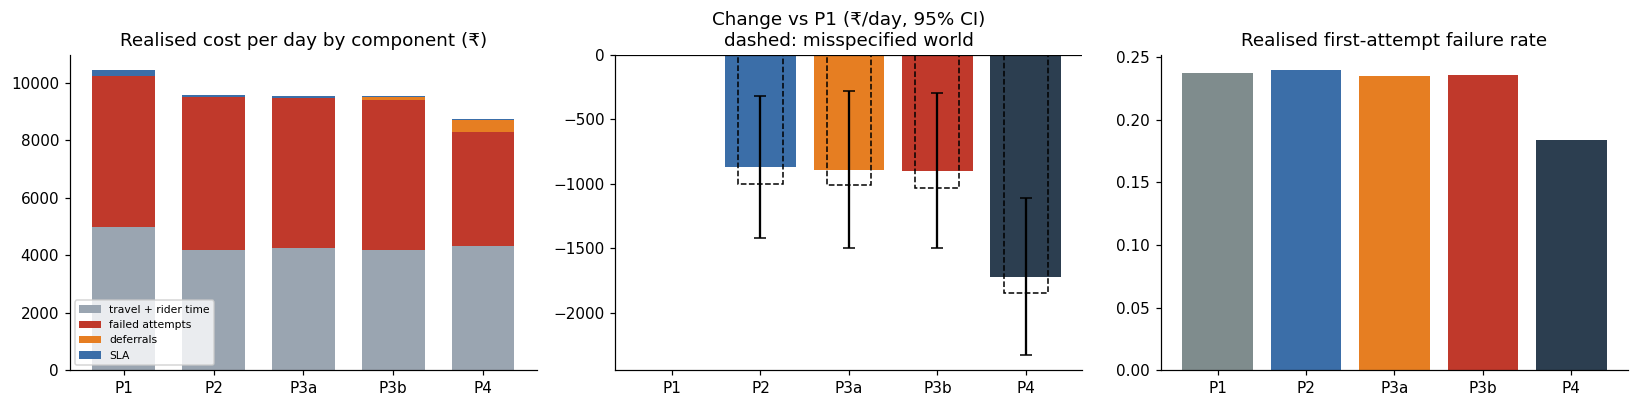

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
short = [n.split(" ")[0] for n in summ.index]
cols = ["#7f8c8d", "#3b6ea8", "#e67e22", "#c0392b", "#2c3e50"]
comp = res[res.scenario == "base"].groupby("planner")[["cost_travel", "cost_fail", "cost_defer", "cost_sla"]].mean().loc[summ.index]
comp.index = short
comp.plot.bar(stacked=True, ax=ax[0], color=["#9aa5b1", "#c0392b", "#e67e22", "#3b6ea8"], width=0.7)
ax[0].set(title="Realised cost per day by component (₹)", xlabel="")
ax[0].legend(["travel + rider time", "failed attempts", "deferrals", "SLA"], fontsize=7)
ax[1].bar(short, summ["vs P1 (₹/day)"], yerr=summ["95% CI ±"], color=cols, capsize=4)
ax[1].bar(short, summ_mis["vs P1 (₹/day)"], color="none", edgecolor="black", ls="--", width=0.5)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set(title="Change vs P1 (₹/day, 95% CI)\ndashed: misspecified world")
ax[2].bar(short, summ["first-attempt fail rate"], color=cols)
ax[2].set(title="Realised first-attempt failure rate")
for a_ in ax:
    a_.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### How to read and present these results
* **Two comparisons, two claims.** *P1 → P3b* is the whole product against the status quo; *P2 → P3b* is what the failure-risk model adds on top of good travel times. Quote both, each with its confidence interval. If an interval crosses zero, say the effect is not distinguishable from zero over this many days (raise `N_EVAL_DAYS` for a tighter estimate).
* **Headroom.** *P2 → P4* is the most that better risk prediction could ever add here; the printed share is how much of it the model captures. The history table in section 3 shows ranking quality by number of past attempts, so the value grows as customers accumulate history.
* **Robustness.** The misspecified rows show whether the gains survive behaviour the models never saw.
* **Deferral.** With these costs, deferring is rarely worth it for the model (its risk estimates are less extreme than the truth); the oracle uses it more. That is a finding, not a bug.
* **Limits.** Behaviour is simulated, so these numbers show that the method works *if* real customers behave roughly like the assumptions. The real-world test is a pilot: alternate days (or riders) between the current planner and this one and compare realised failed attempts and cost.

## 10. Business numbers from the evaluation
Savings are computed from the realised costs above. Prices and volumes are **assumptions to edit**. Plans were optimised with `C_fail` = ₹90; the sensitivity rows re-price the *same* realised outcomes with other failure costs.

In [38]:
PARCELS_PER_DAY = res[(res.scenario == "base") & res.planner.str.startswith("P1")].parcels.mean()
DAYS_PER_MONTH = 30
b = res[res.scenario == "base"].set_index(["day", "planner"])
rows = []
for cf in (60.0, 90.0, 120.0):
    def total(name):
        x = b.xs(name, level="planner")
        return (x.cost_travel + cf * x.failed + x.cost_defer + x.cost_sla).mean()
    for label, ref in (("whole product vs status quo (P1 → P3b)", "P1 Distance-only VRP"),
                       ("risk model alone (P2 → P3b)", "P2 Time-aware (GNN)")):
        s_ = total(ref) - total("P3b Risk-aware (+deferral)")
        rows.append({"comparison": label, "cost per failed attempt (₹)": cf, "saving / day (₹)": s_,
                     "saving / parcel (₹)": s_ / PARCELS_PER_DAY,
                     "saving / month, this cluster (₹)": s_ * DAYS_PER_MONTH})
biz = pd.DataFrame(rows).set_index(["comparison", "cost per failed attempt (₹)"])
print(f"cluster volume ≈ {PARCELS_PER_DAY:.0f} parcels/day, {K_RIDERS} riders")
print(biz.round(2).to_string())
fails_avoided = (summ.iloc[0]["failed / day"] - summ.loc["P3b Risk-aware (+deferral)", "failed / day"])
print(f"failed attempts avoided per 1,000 parcels: {1000 * fails_avoided / PARCELS_PER_DAY:.1f}")

cluster volume ≈ 247 parcels/day, 6 riders
                                                                    saving / day (₹)  saving / parcel (₹)  saving / month, this cluster (₹)
comparison                             cost per failed attempt (₹)                                                                         
whole product vs status quo (P1 → P3b) 60.0                                   875.10                 3.54                          26253.00
risk model alone (P2 → P3b)            60.0                                    -9.58                -0.04                           -287.35
whole product vs status quo (P1 → P3b) 90.0                                   899.10                 3.64                          26973.00
risk model alone (P2 → P3b)            90.0                                    29.42                 0.12                            882.65
whole product vs status quo (P1 → P3b) 120.0                                  923.10                 3.73            

## 11. One day's plan on the map, and exports for the Streamlit app

In [39]:
d_show = eval_days[0]
P_show = DayProblem(d_show)
pl = plans_kept[(d_show, "P3b Risk-aware (+deferral)")]
curves_show = P_show.curve("model")
rows = []
for k, (r, arr) in enumerate(zip(pl["stops"], pl["arrivals"])):
    for seq, (i, h) in enumerate(zip(r, arr)):
        x = (h - H0) / HSTEP
        risk = np.interp(x, np.arange(len(HOUR_GRID)), curves_show[i - 1])
        m = P_show.man.iloc[i - 1]
        rows.append(dict(rider_id=riders.rider_id[k], seq=seq + 1, parcel_id=m.parcel_id, customer_id=m.customer_id,
                         planned_arrival=f"{int(h):02d}:{int((h % 1) * 60):02d}", risk_at_arrival=round(float(risk), 3),
                         min_risk_in_day=round(float(curves_show[i - 1].min()), 3),
                         lat=customers.set_index("customer_id").lat[m.customer_id],
                         lon=customers.set_index("customer_id").lon[m.customer_id]))
plan_table = pd.DataFrame(rows)
os.makedirs("outputs", exist_ok=True)
plan_table.to_csv(f"outputs/plan_{weather.date[d_show]}.csv", index=False)
print(f"plan for {weather.date[d_show]}: {len(plan_table)} stops, {len(pl['deferred'])} deferred")
print(plan_table.head(8).to_string(index=False))

try:
    import folium
    fmap = folium.Map(location=[hub.lat, hub.lon], zoom_start=14, tiles="cartodbpositron")
    palette = ["#1f77b4", "#2ca02c", "#9467bd", "#8c564b", "#e377c2", "#17becf"]
    for k, g in plan_table.groupby("rider_id"):
        c = palette[int(k[1:]) - 1]
        pts = [[hub.lat, hub.lon]] + g[["lat", "lon"]].values.tolist() + [[hub.lat, hub.lon]]
        folium.PolyLine(pts, color=c, weight=2, opacity=0.6, tooltip=f"{k}").add_to(fmap)
        for _, s in g.iterrows():
            folium.CircleMarker([s.lat, s.lon], radius=4, color=c, fill=True,
                                fill_color="#c0392b" if s.risk_at_arrival > 0.3 else c, fill_opacity=0.9,
                                tooltip=f"{k} #{s.seq} {s.planned_arrival} risk {s.risk_at_arrival:.2f}").add_to(fmap)
    folium.Marker([hub.lat, hub.lon], tooltip="hub").add_to(fmap)
    fmap.save("outputs/plan_map.html")
    display(fmap)
except Exception as e:
    print("map skipped:", e)

plan for 2026-08-30: 222 stops, 0 deferred
rider_id  seq parcel_id customer_id planned_arrival  risk_at_arrival  min_risk_in_day       lat       lon
      R1    1  P0016936      C02723           09:15            0.223            0.151 12.921385 77.636038
      R1    2  P0017100      C02716           09:24            0.113            0.110 12.918502 77.635229
      R1    3  P0017064      C01352           09:30            0.057            0.031 12.915119 77.638731
      R1    4  P0017058      C01156           09:38            0.187            0.178 12.915135 77.644188
      R1    5  P0016851      C00243           09:48            0.092            0.090 12.911390 77.642340
      R1    6  P0017079      C01808           09:53            0.212            0.209 12.908508 77.640223
      R1    7  P0016972      C04126           10:00            0.321            0.296 12.906670 77.638666
      R1    8  P0017167      C04871           10:03            0.237            0.192 12.906970 77.639140


In [40]:
os.makedirs("artifacts", exist_ok=True)
xgbm.save_model("artifacts/failure_xgb.json")
torch.save(failnet.state_dict(), "artifacts/failnet.pt")
torch.save(gnn.state_dict(), "artifacts/travel_gnn.pt")
json.dump(dict(features=FEATURES, hour_grid=HOUR_GRID.tolist(), selected_failure_model=BEST_FAIL,
               cost=COST, shifts=SHIFTS, capacity=CAP), open("artifacts/config.json", "w"), indent=1)
fail_metrics.to_csv("outputs/failure_model_metrics.csv")
tt_metrics.to_csv("outputs/travel_time_metrics.csv")
res.to_csv("outputs/planner_results_by_day.csv", index=False)
summ.to_csv("outputs/planner_summary.csv"); summ_mis.to_csv("outputs/planner_summary_misspecified.csv")
biz.to_csv("outputs/business_numbers.csv")
subprocess.run("zip -qr lastmile_outputs.zip outputs artifacts", shell=True)
print("saved outputs/ and artifacts/ (zipped as lastmile_outputs.zip)")

saved outputs/ and artifacts/ (zipped as lastmile_outputs.zip)
